# D36. 준언어 · 소리 이벤트 분석: 말투와 주변 소리로 통화를 읽기

**음성 AI 전문가 과정 | 8주차 M8 차세대 음성 모델 · 다국어 · 데이터 · TTS 파인튜닝 | 4시간**

## 학습 목표
1. 말의 **내용이 아닌 말투**(준언어: 높낮이 · 크기 · 말속도 · 쉼)를 숫자로 재고, **그 사람의 평소 말투(기준선)** 와 비교해 '들뜸' 신호를 만든다.
2. 감정 인식 모델(emotion2vec+)을 연기 음성으로 시험해 **무엇을 맞히고 무엇을 틀리는지** 확인하고, 확신이 낮으면 **'불확실'로 답을 미루는** 판정과 감정 타임라인을 만든다.
3. 소리 이벤트를 **정해진 목록으로 분류**(AST)하는 방법과 **글로 물어보는 제로샷 분류**(CLAP)를 비교하고, 긴 녹음에서 이벤트 구간을 찾는다.
4. 통화 1건의 **신호 표 · 타임라인 · 요약 리포트**를 만들고, 상담원 연결 · 긴급 확인 **에스컬레이션 규칙**을 직접 작성한다. 감정 추정의 **한계와 쓰면 안 되는 곳**을 말할 수 있다.

## 오늘의 실습 흐름
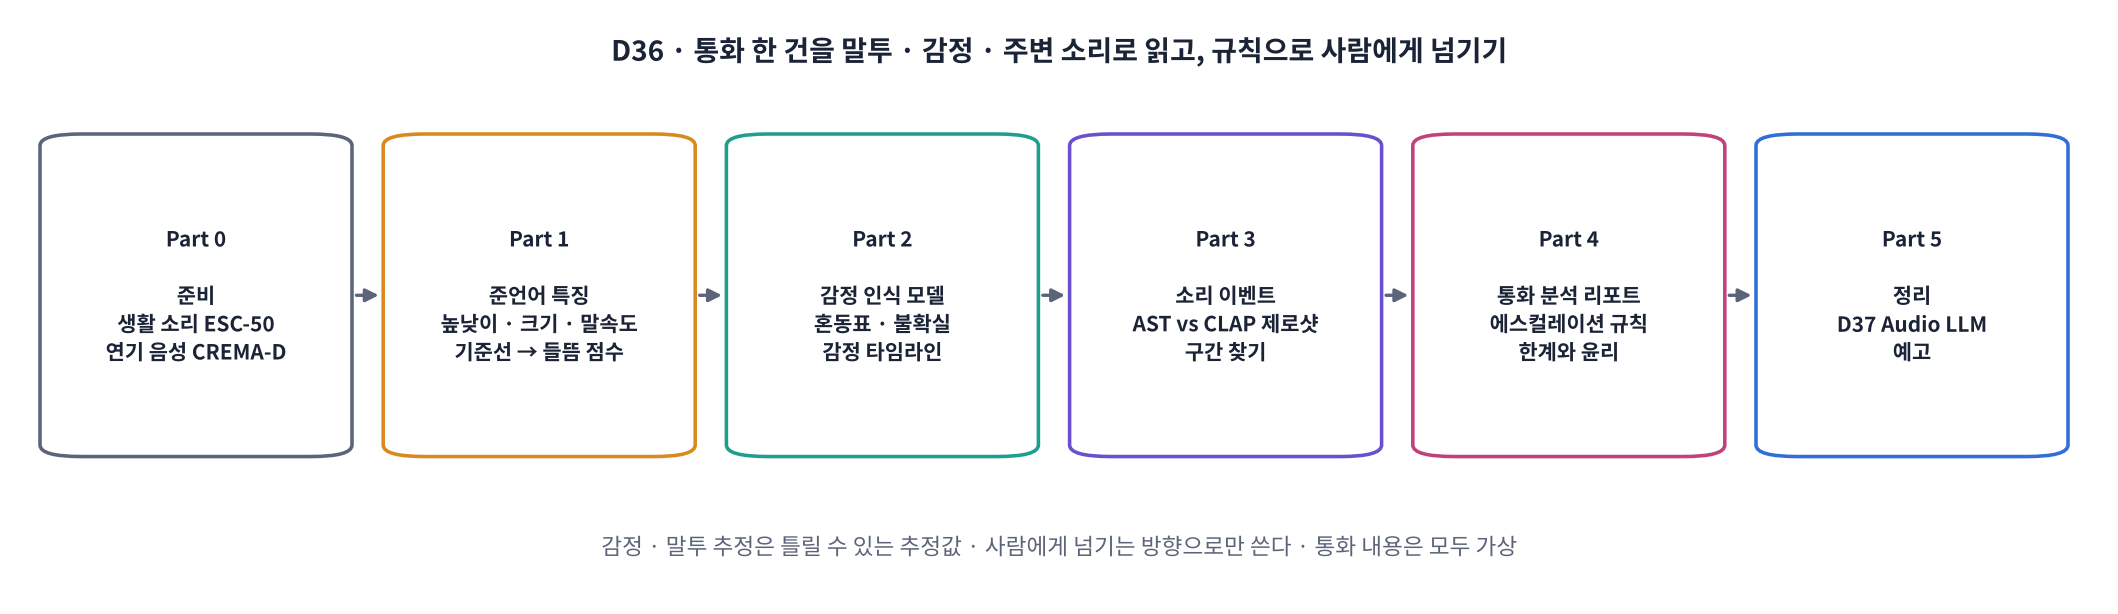

| 교시 | 내용 | 실습 | 산출물 |
|---|---|---|---|
| 1교시 | 준언어 특징: 높낮이(F0) · 크기 · 말속도 · 쉼, 기준선과 비교 | Part 0 ~ 1 · ✍️ 직접 작성 1 (반음 차이) | 말투별 특징 표 · 들뜸 점수 |
| 2교시 | 감정 인식 모델, 혼동표, '불확실' 판정, 감정 타임라인 | Part 2 · ✍️ 직접 작성 2 (확신 문턱) | 혼동표 · 답한 비율 vs 정확도 · 타임라인 |
| 3교시 | 소리 이벤트: AST(정해진 목록) vs CLAP(제로샷), 긴 녹음에서 구간 찾기 | Part 3 · ✍️ 직접 작성 3 (구간 겹침) | 분류 비교표 · 프롬프트 비교 · 이벤트 구간 표 |
| 4교시 | 통화 분석 리포트, 에스컬레이션 규칙, 한계와 윤리 | Part 4 ~ 5 · ✍️ 직접 작성 4 (에스컬레이션 규칙) · 워크시트 25문항 | 통화 신호 표 · 타임라인 · 요약 리포트 |

## 오늘의 수업 자료
| 자료 | 링크 | 언제 쓰나요 |
|---|---|---|
| 🎬 인터랙티브 애니메이션 | [animation.html](https://imguru-mooc.github.io/AI_Voice/day36/animation.html) | 준언어 특징(D36-2) · 기준선(D36-3) · 감정과 확신(D36-4) · 타임라인 다듬기(D36-5) · AST와 CLAP(D36-6) · 이벤트 구간 찾기(D36-7) · 에스컬레이션 규칙(D36-8). 탭마다 **▶ 시연 보기**를 누르면 자막과 함께 스스로 움직입니다 |
| 📝 개념 워크시트 | [worksheet.html](https://imguru-mooc.github.io/AI_Voice/day36/worksheet.html) | 수업을 모두 마친 뒤 하루 한 장 25문항 (객관식 · OX · 모두 고르기 · 선 잇기 · 순서 · 코드 직접 쓰기 · 계산 · 분류 · 직접 조작), 오답 정리 → 노션 |

## 이 노트북 사용법
- ▶️ 위에서부터 차례로 실행합니다. **키가 필요 없습니다.**
- ⭐ **핵심 코드** 셀은 완성된 코드입니다. 실행한 뒤 `# ⭐` 표시가 붙은 줄을 읽어 보세요. 🔍 **핵심 줄 해설 보기**를 누르면 설명이 펼쳐집니다.
- ✍️ **직접 작성** 셀은 교시마다 하나씩, 모두 네 개입니다. `...` 자리에 코드를 직접 쓰고 실행하면 ✅ 또는 ❌가 나옵니다. 막히면 💡 **힌트 보기**, 다 쓴 뒤에는 🔑 **정답 보기**를 누르세요. 작성하지 않아도 아래 셀은 그대로 실행됩니다.
- ✏️ 표시 줄은 값을 **직접 바꿔** 다시 실행해 보는 줄입니다.

| 표시 | 뜻 |
|---|---|
| 💬 **쉽게 말하면** | 그 절의 내용을 한 문장으로 |
| 🍎 **비유** | 일상의 장면으로 바꿔 보기 |
| 👣 **한 단계씩** | 무슨 일이 어떤 순서로 일어나는지 |
| 📐 **핵심 식 하나** | 꼭 기억할 규칙 하나 |
| ❓ **생각해 보기** | 스스로 답해 보고 펼쳐서 확인 |
| 🎧 **들어 보기** | 소리로 확인 |

> ⚙️ **런타임 → T4 GPU** 권장. 오늘 쓰는 사람 목소리는 **공개 데이터의 연기 음성**과 **합성 음성**뿐입니다. 이름 · 통화 내용은 모두 가상입니다.
>
> ⚖️ **오늘의 약속**: 감정 · 말투 추정은 **틀릴 수 있는 추정값**입니다. 사람을 평가하거나 불이익을 주는 데 쓰지 않습니다(Part 4).

> 🎬 **애니메이션 D36-1:** [오늘의 흐름](https://imguru-mooc.github.io/AI_Voice/day36/animation.html#flow) — 통화 한 건이 말투 · 감정 · 주변 소리 신호로 나뉘어 규칙에 닿는 과정

## Part 0. 준비

> 🛠️ 감정 인식 `funasr`(emotion2vec+)만 새로 설치합니다. 소리 분류 AST · CLAP은 `transformers`에 있고, 높낮이 · 크기는 `librosa`로 잽니다. Whisper · Edge TTS는 D27 ~ D35와 같습니다.

In [ ]:
# 📦 설치: Colab 기본 패키지 버전은 그대로 고정하고 필요한 것만 추가 (런타임 재시작 불필요, 1 ~ 2분)
import importlib.metadata as md
KEEP = ["torch", "torchaudio", "torchvision", "torchcodec", "transformers", "tokenizers", "huggingface-hub", "datasets",
        "accelerate", "diffusers", "numpy", "scipy", "librosa", "numba", "safetensors", "requests",
        "click", "filelock", "rich", "typer", "pydantic", "httpx"]
pins = []
for p in KEEP:
    try:
        pins.append(f"{p}=={md.version(p)}")
    except md.PackageNotFoundError:
        pass
open("colab_constraints.txt", "w").write("\n".join(pins) + "\n")
print("고정한 버전:", ", ".join(pins))
!pip install -q -c colab_constraints.txt soundfile uroman edge-tts
!pip install -q -c colab_constraints.txt funasr          # 감정 인식 emotion2vec+ (설치가 안 되면 아래에서 예비 모델로 자동 전환)
print("✅ 설치 완료")

In [ ]:
import os, re, io, sys, json, time, random, warnings, logging, tempfile, functools
import numpy as np
import pandas as pd
import librosa
import torch
import requests
import soundfile as sf
import matplotlib.pyplot as plt
from scipy import signal
from IPython.display import Audio, display, Markdown
from transformers import pipeline                        # 소리 분류(AST) · 제로샷 소리 분류(CLAP)를 한 줄로 부르는 도구
import importlib.metadata as md
warnings.filterwarnings("ignore")
logging.getLogger("transformers").setLevel(logging.ERROR)

GPU = torch.cuda.is_available()
DEVICE = "cuda" if GPU else "cpu"
SR = 16000                                               # 말소리 분석용 (Whisper · 감정 · AST)
SR48 = 48000                                             # CLAP이 듣는 표본화율
print(" · ".join(f"{p} {md.version(p)}" for p in ["transformers", "librosa", "torch"]))
print("GPU:", torch.cuda.get_device_name(0) if GPU else "없음 (CPU로도 가능, 조금 느림)")

def verify(cond, what=""):                               # ⭐ 핵심 코드 셀: 결과가 예상과 같은지 스스로 확인
    print(f"✅ 확인: {what}" if cond else f"⚠️ 예상과 다릅니다: {what} → 위 셀을 고쳤다면 원래대로 되돌려 다시 실행하세요.")

def practice(run, want, tol=1e-4):                       # ✍️ 직접 작성 셀 채점: 아직 안 썼거나 오류가 나도 노트북은 계속 실행됨
    try:
        got = run()
    except Exception as e:
        print(f"❌ 실행 중 오류가 났습니다 ({type(e).__name__}: {str(e)[:90]}) · 아래 💡 힌트 보기를 눌러 보세요."); return False
    items = got if isinstance(got, (list, tuple)) else [got]
    if any(x is None or x is Ellipsis for x in items):
        print("✍️ 아직 작성 전입니다. '...' 줄을 지우고 코드를 쓴 뒤 다시 실행하세요. (작성하지 않아도 아래 셀은 그대로 실행됩니다)"); return False
    try:
        ok = bool(np.allclose(np.asarray(got, float), np.asarray(want, float), atol=tol))
    except (TypeError, ValueError):
        ok = list(items) == list(want if isinstance(want, (list, tuple)) else [want])
    show = lambda v: str([round(float(x), 4) if isinstance(x, (int, float, np.floating)) else x for x in (v if isinstance(v, (list, tuple)) else [v])])[:110]
    print("✅ 정답입니다! 🎉" if ok else f"❌ 결과가 다릅니다. 내 결과 {show(got)} · 기대 {show(want)} · 아래 💡 힌트 보기를 눌러 보세요.")
    return ok

def set_seed(s=0):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if GPU: torch.cuda.manual_seed_all(s)

def to_np(y):
    y = y.detach().cpu().numpy() if torch.is_tensor(y) else np.asarray(y)
    return y.reshape(-1).astype(np.float32)

def play(y, sr=SR, label=""):
    y = to_np(y)
    print(f"🎧 {label}  ({len(y) / sr:.2f}초)")
    if len(y): display(Audio(y, rate=sr))
    else: print("   (소리 없음: 위의 경고 · 오류를 확인하세요)")

def silence(sec, sr=SR):
    return np.zeros(int(sec * sr), np.float32)

In [ ]:
# 🔊 모델 준비 (D27 ~ D35와 같음): 받아쓰기 Whisper · 합성 Edge TTS (예비 MMS-TTS) + 오늘의 손님 말 한 마디
from transformers import AutoTokenizer, VitsModel, WhisperProcessor, WhisperForConditionalGeneration
import uroman as ur
tts_tok = AutoTokenizer.from_pretrained("facebook/mms-tts-kor")
tts_model = VitsModel.from_pretrained("facebook/mms-tts-kor").to(DEVICE).eval()
U = ur.Uroman()
ASR_NAME = "openai/whisper-small" if GPU else "openai/whisper-tiny"
asr_proc = WhisperProcessor.from_pretrained(ASR_NAME)
asr = WhisperForConditionalGeneration.from_pretrained(ASR_NAME).to(DEVICE).eval()

import functools, tempfile
VOICE_BOT, VOICE_USER = "ko-KR-SunHiNeural", "ko-KR-InJoonNeural"   # ✏️ Edge 신경망 음성: 비서 · 사용자 대역
TTS_ENGINE = "edge"                                      # 인터넷 · 서비스 문제로 실패하면 자동으로 "mms"(예비)

@functools.lru_cache(maxsize=512)                        # 같은 문장은 다시 요청하지 않음
def _edge_tts(text, voice):
    import edge_tts
    fd, path = tempfile.mkstemp(suffix=".mp3"); os.close(fd)
    try:
        edge_tts.Communicate(text, voice).save_sync(path)
        return librosa.load(path, sr=SR)[0].astype(np.float32)   # MP3 24 kHz → 16 kHz
    finally:
        os.remove(path)

def _mms_tts(text, seed=0):                              # 예비: MMS-TTS 한국어 VITS (D16)
    set_seed(seed)
    enc = tts_tok(U.romanize_string(text), return_tensors="pt").to(DEVICE)
    with torch.no_grad():
        return to_np(tts_model(**enc).waveform[0])

def tts(text, seed=0, voice=None):                       # 글자 → 16 kHz 소리: Edge 신경망 음성, 실패하면 MMS-TTS
    global TTS_ENGINE
    if TTS_ENGINE == "edge":
        try:
            return _edge_tts(text, voice or VOICE_BOT).copy()
        except Exception as e:
            print(f"⚠️ Edge TTS 실패 → MMS-TTS로 전환 ({type(e).__name__}: {str(e)[:80]})"); TTS_ENGINE = "mms"
    return _mms_tts(text, seed)

def user_tts(text, seed=0):                              # 사용자 대역 목소리: 비서와 다른 목소리 (MMS 예비일 때는 3반음 낮춰 구분)
    y = tts(text, seed=seed, voice=VOICE_USER)
    return librosa.effects.pitch_shift(y, sr=SR, n_steps=-3) if TTS_ENGINE == "mms" else y

def stt(y):                                              # 16 kHz 소리 → 글자
    feats = asr_proc.feature_extractor(to_np(y), sampling_rate=SR, return_tensors="pt").input_features.to(DEVICE)
    with torch.no_grad():
        ids = asr.generate(input_features=feats, language="korean", task="transcribe", max_new_tokens=96)
    return asr_proc.batch_decode(ids, skip_special_tokens=True)[0].strip()

def make_voice(text):                                    # 앞 0.5초 · 뒤 1초 조용함을 붙인 '사용자 말'
    y = np.concatenate([silence(0.5), user_tts(text), silence(1.0)]).astype(np.float32)
    return y / (np.abs(y).max() + 1e-9) * 0.8

# 오늘의 장면: 한빛치과에 전화한 손님의 말투가 통화 중에 달라짐
LINE = "내일 오후 세 시 예약을 확인하고 싶어요."
play(tts(LINE, voice=VOICE_USER), SR, "손님 (평소 말투)")
print("받아쓰기 확인:", stt(tts(LINE, voice=VOICE_USER)))

In [ ]:
# 📥 오늘의 소리 재료 (파일을 하나씩 내려받음, 약 1분 · 22 MB)
#   ① 생활 소리 ESC-50: 8종 × 5개 (CC BY-NC · 수업용)   ② 연기한 감정 음성 CREMA-D: 배우 4명 × 감정 6가지 × 2문장 (영어 · ODbL)
ESC_RAW = "https://raw.githubusercontent.com/karolpiczak/ESC-50/master/"
CREMA_RAW = "https://media.githubusercontent.com/media/CheyneyComputerScience/CREMA-D/master/AudioWAV/"
EVENTS = {"glass_breaking": "유리 깨짐", "coughing": "기침", "crying_baby": "아기 울음", "siren": "사이렌",
          "door_wood_knock": "문 두드림", "dog": "개 짖음", "sneezing": "재채기", "footsteps": "발소리"}
CREMA_EMO = {"ANG": "angry", "DIS": "disgusted", "FEA": "fearful", "HAP": "happy", "NEU": "neutral", "SAD": "sad"}
ACTORS, SENTS = ["1001", "1002", "1003", "1004"], {"ITS": "I think I have a doctor's appointment.", "DFA": "Don't forget a jacket."}

def fetch_wav(url, sr):                                  # 주소의 소리 파일 → 원하는 표본화율의 1채널 배열
    r = requests.get(url, timeout=30); r.raise_for_status()
    y, s = sf.read(io.BytesIO(r.content), dtype="float32")
    y = y.mean(axis=1) if y.ndim > 1 else y
    return librosa.resample(y, orig_sr=s, target_sr=sr) if s != sr else y

def load_esc(n_per=5):
    meta = pd.read_csv(io.StringIO(requests.get(ESC_RAW + "meta/esc50.csv", timeout=30).text))
    rows = []
    for cat, ko in EVENTS.items():
        for f in meta[meta.category == cat].filename.head(n_per):
            y48 = fetch_wav(ESC_RAW + "audio/" + f, SR48)
            rows.append({"cat": cat, "ko": ko, "file": f, "wav48": y48, "wav": librosa.resample(y48, orig_sr=SR48, target_sr=SR)})
    return pd.DataFrame(rows)

def load_crema():
    rows = []
    for a in ACTORS:
        for s in SENTS:
            for code, emo in CREMA_EMO.items():
                try:
                    rows.append({"actor": a, "sent": s, "emo": emo, "wav": fetch_wav(f"{CREMA_RAW}{a}_{s}_{code}_XX.wav", SR)})
                except Exception:
                    pass                                 # 빠진 파일은 건너뜀
    return pd.DataFrame(rows)

def fake_events():                                       # 예비: 내려받기 실패 시 만든 소리 3종 (결과 숫자는 의미 없음, 흐름만 확인)
    rng, rows = np.random.default_rng(0), []
    t = np.arange(5 * SR48) / SR48
    for k in range(5):
        siren = 0.3 * np.sin(2 * np.pi * (700 + 300 * np.sin(2 * np.pi * (0.5 + 0.1 * k) * t)) * t)
        knock = np.zeros_like(t); glass = np.zeros_like(t)
        for s in (0.5, 0.9, 1.3 + 0.1 * k): knock[int(s * SR48):int(s * SR48) + 2400] = rng.standard_normal(2400) * np.exp(-np.arange(2400) / 300) * 0.6
        n = int(0.8 * SR48); glass[SR48:SR48 + n] = signal.sosfilt(signal.butter(4, 4000 + 300 * k, "high", fs=SR48, output="sos"), rng.standard_normal(n)) * np.exp(-np.arange(n) / 9000) * 0.5
        for cat, y in [("siren", siren), ("door_wood_knock", knock), ("glass_breaking", glass)]:
            y = y.astype(np.float32); rows.append({"cat": cat, "ko": EVENTS[cat], "file": f"made-{cat}-{k}", "wav48": y, "wav": librosa.resample(y, orig_sr=SR48, target_sr=SR)})
    return pd.DataFrame(rows)

try:
    ESC, ESC_NAME = load_esc(), "ESC-50 (실제 녹음)"
except Exception as e:
    print(f"⚠️ ESC-50을 내려받지 못함 → 만든 소리 3종으로 대신 ({type(e).__name__}: {str(e)[:80]})")
    ESC, ESC_NAME = fake_events(), "만든 소리 (예비: 숫자는 의미 없음)"
try:
    ACT = load_crema()
    if len(ACT) < 12: raise RuntimeError(f"{len(ACT)}개만 받음")
except Exception as e:
    print(f"⚠️ CREMA-D를 내려받지 못함 → 감정 모델 시험(2교시 혼동표)은 건너뜀 ({type(e).__name__}: {str(e)[:80]})")
    ACT = pd.DataFrame(columns=["actor", "sent", "emo", "wav"])
CATS = list(dict.fromkeys(ESC.cat))                      # 실제로 준비된 소리 종류
print(f"생활 소리: {ESC_NAME} {len(ESC)}개 ({' · '.join(EVENTS[c] for c in CATS)})")
print(f"연기한 감정 음성: CREMA-D {len(ACT)}개 (배우 {ACT.actor.nunique()}명 · 감정 {ACT.emo.nunique()}가지)")
for c in CATS[:3]:
    r = ESC[ESC.cat == c].iloc[0]; play(r.wav, SR, f"생활 소리: {r.ko}")
if len(ACT):
    for e in ["neutral", "angry", "sad"]:
        r = ACT[ACT.emo == e].iloc[0]; play(r.wav, SR, f"연기한 감정 ({e}): {SENTS[r.sent]}")

## Part 1. 준언어 특징: 무엇을 말했나가 아니라 '어떻게' 말했나  ·  1교시

받아쓰기(STT)는 "예약을 확인하고 싶어요"라는 **글자**만 남깁니다. 같은 문장을 차분하게 말했는지, 서둘러 말했는지, 큰 소리로 말했는지는 글자에 없습니다. 이 '글자 밖의 정보'를 **준언어(paralinguistic) 정보**라고 합니다.

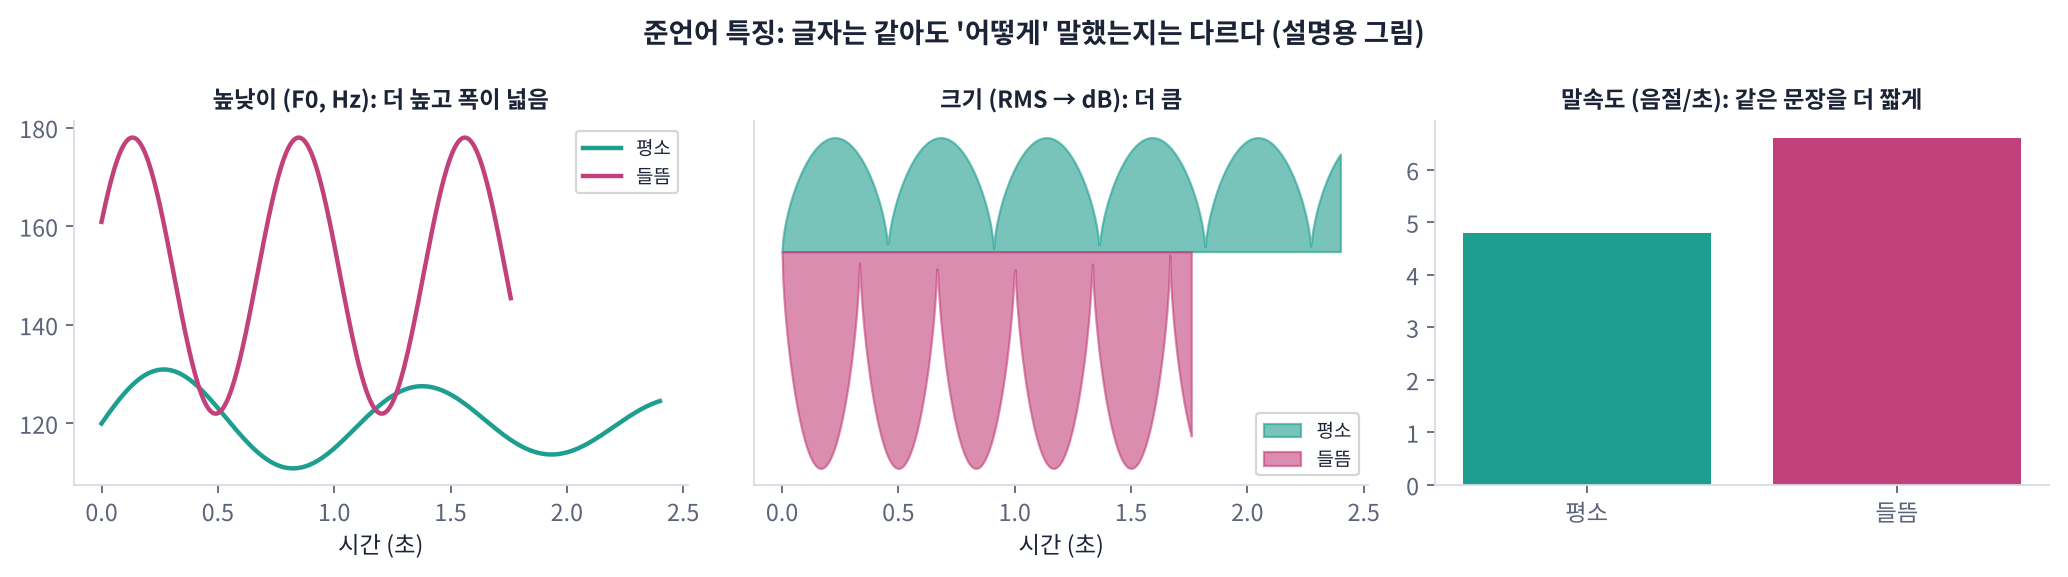

| 특징 | 재는 것 | 도구 | 단위 |
|---|---|---|---|
| **높낮이 (F0)** | 성대가 1초에 떨리는 횟수 | `librosa.pyin` | Hz, 비교는 **반음** |
| **크기** | 소리의 세기 | `librosa.feature.rms` | dB |
| **말속도** | 1초에 말한 음절 수 | 글자 수 ÷ 말한 시간 | 음절/초 |
| **쉼 비율** | 말 사이 조용한 시간의 비율 | 크기가 작은 구간 | 0 ~ 1 |

> 💬 **쉽게 말하면**: 목소리의 '음표 · 볼륨 · 템포'를 재는 일입니다. 감정을 바로 알아내는 것이 아니라, **평소와 달라졌다는 신호**를 만드는 것이 목표입니다.

> 🍎 **비유**: 가족의 전화 목소리를 들으면 "무슨 일 있어?"라고 묻게 될 때가 있습니다. 말의 내용이 아니라 **평소보다** 빠르고 높고 큰 말투를 들었기 때문입니다. 처음 듣는 사람의 목소리로는 그 판단이 어렵습니다. 오늘 '기준선'이 중요한 이유입니다.

> 🎬 **애니메이션 D36-2:** [준언어 특징](https://imguru-mooc.github.io/AI_Voice/day36/animation.html#prosody) — 말속도 · 높낮이 · 크기를 바꾸면 파형과 세 숫자가 어떻게 달라지는지

In [ ]:
# 🎭 같은 문장, 다른 말투 만들기: Edge TTS의 빠르기 · 높이 · 크기 조절 (사람의 실제 감정이 아니라 '말투 흉내'입니다)
STYLES = {"차분": dict(rate=0, pitch=0, vol=0), "서두름": dict(rate=35, pitch=20, vol=10),
          "큰 소리": dict(rate=10, pitch=35, vol=40), "가라앉음": dict(rate=-20, pitch=-15, vol=-20)}   # ✏️ 값을 바꿔 보세요 (%, Hz, %)

@functools.lru_cache(maxsize=256)
def _styled(text, voice, rate, pitch, vol):
    import edge_tts
    fd, path = tempfile.mkstemp(suffix=".mp3"); os.close(fd)
    try:
        edge_tts.Communicate(text, voice, rate=f"{rate:+d}%", pitch=f"{pitch:+d}Hz", volume=f"{vol:+d}%").save_sync(path)
        return librosa.load(path, sr=SR)[0].astype(np.float32)
    finally:
        os.remove(path)

def act(text, style="차분", voice=None):                 # 글자 + 말투 → 16 kHz 소리
    global TTS_ENGINE
    s, voice = STYLES[style], voice or VOICE_USER
    if TTS_ENGINE == "edge":
        try:
            return _styled(text, voice, s["rate"], s["pitch"], s["vol"]).copy()
        except Exception as e:
            print(f"⚠️ Edge TTS 실패 → MMS-TTS + 소리 가공으로 전환 ({type(e).__name__}: {str(e)[:80]})"); TTS_ENGINE = "mms"
    y = tts(text, voice=voice)                           # 예비: 평범하게 합성한 뒤 빠르기 · 높이 · 크기를 직접 바꿈
    if s["rate"]: y = librosa.effects.time_stretch(y, rate=1 + s["rate"] / 100)
    if s["pitch"]: y = librosa.effects.pitch_shift(y, sr=SR, n_steps=s["pitch"] / 8)
    return (y * (1 + s["vol"] / 100)).astype(np.float32)

SAY = {k: act(LINE, k) for k in STYLES}
for k, y in SAY.items(): play(y, SR, f"{k}: {LINE}")

In [ ]:
# ⭐ 핵심 코드: 말투를 숫자 네 개로 — 높낮이 · 크기 · 쉼 · 말속도
HOP = 320                                                # 20 ms마다 한 번 잼

def prosody(y, text=None):
    y = to_np(y)
    f0, _, _ = librosa.pyin(y, fmin=70, fmax=400, sr=SR, frame_length=1024, hop_length=HOP)   # ⭐ 조각마다 높낮이(Hz), 목소리가 아니면 NaN
    rms = librosa.feature.rms(y=y, frame_length=640, hop_length=HOP)[0]                       # ⭐ 조각마다 크기
    db = 20 * np.log10(rms + 1e-9)
    speech = db > db.max() - 30                          # 가장 큰 곳보다 30 dB 넘게 작으면 '쉼'
    idx = np.where(speech)[0]; core = speech[idx[0]:idx[-1] + 1]      # 첫 말 ~ 마지막 말 사이
    talk = speech.sum() * HOP / SR                       # 실제로 말한 시간(초)
    f0v = f0[~np.isnan(f0)]
    out = {"높낮이(Hz)": float(np.median(f0v)) if len(f0v) else np.nan,
           "높낮이 폭(반음)": float(12 * np.log2(np.percentile(f0v, 90) / np.percentile(f0v, 10))) if len(f0v) > 5 else np.nan,
           "크기(dB)": float(db[speech].mean()), "쉼 비율": float(1 - core.mean()), "말한 시간(초)": float(talk)}
    if text: out["말속도(음절/초)"] = len(re.findall("[가-힣]", text)) / talk     # ⭐ 한글 한 글자 = 한 음절
    return out

FEAT = {k: prosody(y, LINE) for k, y in SAY.items()}
df_p = pd.DataFrame(FEAT).T.round(2); display(df_p)
fig, ax = plt.subplots(1, 2, figsize=(12, 3))
for k, y in SAY.items():
    f0 = librosa.pyin(to_np(y), fmin=70, fmax=400, sr=SR, frame_length=1024, hop_length=HOP)[0]
    ax[0].plot(np.arange(len(f0)) * HOP / SR, f0, ".", ms=3, label=k)
ax[0].set_xlabel("time (s)"); ax[0].set_ylabel("F0 (Hz)"); ax[0].set_title("pitch contour of the same sentence in 4 styles", fontsize=10); ax[0].legend(["calm", "hurried", "loud", "low"], fontsize=8)
ax[1].bar(["calm", "hurried", "loud", "low"], df_p["말속도(음절/초)"], color=["#1E9E8F", "#D98A1E", "#C2417A", "#6A4FCF"]); ax[1].set_ylabel("syllables / s"); ax[1].set_title("speech rate", fontsize=10)
plt.tight_layout(); plt.show()
verify(FEAT["서두름"]["말속도(음절/초)"] > FEAT["차분"]["말속도(음절/초)"] > FEAT["가라앉음"]["말속도(음절/초)"] and FEAT["큰 소리"]["높낮이(Hz)"] > FEAT["차분"]["높낮이(Hz)"],
       "서두른 말이 가장 빠르고, 큰 소리로 말한 쪽의 높낮이가 차분한 말보다 높음")

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
f0, _, _ = librosa.pyin(y, fmin=70, fmax=400, sr=SR, frame_length=1024, hop_length=HOP)
rms = librosa.feature.rms(y=y, frame_length=640, hop_length=HOP)[0]
out["말속도(음절/초)"] = len(re.findall("[가-힣]", text)) / talk
```

**해설**: `pyin`은 조각마다 '성대가 떨리는 주기'를 찾아 높낮이(F0)를 Hz로 돌려줍니다. 숨소리나 ㅅ · ㅊ 같은 소리는 성대가 떨리지 않아 `NaN`이 되므로 평균이 아니라 **NaN을 뺀 중앙값**을 씁니다(튀는 값에 강함). `fmin=70, fmax=400`은 어른 목소리의 범위입니다. 아이 목소리까지 재려면 `fmax`를 600쯤으로 올립니다. `rms`는 조각 안 표본들의 제곱 평균의 제곱근으로, 로그(`20·log10`)를 씌워 dB로 봅니다. 말속도는 한국어에서 **한글 한 글자가 한 음절**이라는 점을 이용해 글자 수를 '실제로 말한 시간'으로 나눕니다. 쉼을 포함한 전체 길이로 나누면 머뭇거리는 사람이 느리게 말한 것처럼 보입니다. 크기(dB)는 **녹음 장비와 마이크 거리**에 따라 달라지는 값이라, 서로 다른 통화끼리 비교하지 않고 같은 통화 안에서의 변화만 봅니다.

</details>

### 1-1. 기준선: 숫자 그 자체가 아니라 '평소와의 차이'

높낮이 180 Hz는 높은 걸까요? 남성에게는 꽤 높고 여성에게는 낮은 편입니다. 말속도 6음절/초도 원래 말이 빠른 사람에게는 평소입니다. 그래서 **통화 처음 몇 마디를 그 사람의 기준선**으로 삼고, 이후 말투를 기준선과 비교합니다.

📐 **핵심 식 하나**: 높낮이 차이는 Hz의 뺄셈이 아니라 **비율의 로그**로 봅니다. `반음 = 12 × log2(f / 기준)`. 100 → 200 Hz와 200 → 400 Hz는 둘 다 12반음(한 옥타브)으로, 귀에는 같은 크기의 변화로 들립니다.

👣 **한 단계씩**
1. 통화 첫 발화의 특징을 **기준선**으로 저장
2. 새 발화마다 말속도는 **비율**, 높낮이는 **반음**, 크기는 **dB 차이**로 기준선과 비교
3. 세 차이를 가중해 더한 값을 **들뜸 점수**로 (0 = 평소, 클수록 빠르고 높고 큼)

> 🎬 **애니메이션 D36-3:** [기준선](https://imguru-mooc.github.io/AI_Voice/day36/animation.html#baseline) — 목소리가 높은 사람과 낮은 사람: 절대 문턱은 틀리고 기준선 비교는 맞는 모습

In [ ]:
# ⭐ 핵심 코드: 기준선과 비교한 '들뜸 점수'
W_RATE, W_PITCH, W_LOUD = 2.0, 0.25, 0.08                # ✏️ 가중치: 말속도 50% 빨라짐 = 1.0 · 높낮이 4반음 = 1.0 · 크기 12.5 dB = 1.0
AROUSAL_TH = 1.0                                         # ✏️ 이 이상이면 '들뜸' 신호

def arousal(feat, base):
    d_rate = feat["말속도(음절/초)"] / base["말속도(음절/초)"] - 1                 # ⭐ 말속도: 기준선 대비 비율
    d_pitch = 12 * np.log2(feat["높낮이(Hz)"] / base["높낮이(Hz)"])                # ⭐ 높낮이: 기준선 대비 반음
    d_loud = feat["크기(dB)"] - base["크기(dB)"]                                    # ⭐ 크기: dB 차이
    return float(W_RATE * d_rate + W_PITCH * d_pitch + W_LOUD * d_loud)

BASE = FEAT["차분"]                                       # 이 사람의 평소 말투
df_a = pd.DataFrame([{"말투": k, "말속도 변화": f"{f['말속도(음절/초)'] / BASE['말속도(음절/초)'] - 1:+.0%}",
                      "높낮이 변화(반음)": round(12 * np.log2(f["높낮이(Hz)"] / BASE["높낮이(Hz)"]), 1),
                      "크기 변화(dB)": round(f["크기(dB)"] - BASE["크기(dB)"], 1), "들뜸 점수": round(arousal(f, BASE), 2),
                      "신호": "들뜸" if arousal(f, BASE) >= AROUSAL_TH else ("가라앉음" if arousal(f, BASE) <= -AROUSAL_TH else "평소")} for k, f in FEAT.items()])
display(df_a)

# 목소리가 원래 높은 사람(여성 목소리)의 '차분한 말' vs 목소리가 낮은 사람(남성 목소리)의 '큰 소리'
hi_calm = prosody(act(LINE, "차분", VOICE_BOT), LINE)
print(f"높은 목소리의 차분한 말: {hi_calm['높낮이(Hz)']:.0f} Hz  vs  낮은 목소리의 큰 소리: {FEAT['큰 소리']['높낮이(Hz)']:.0f} Hz")
print("→ '몇 Hz 이상이면 흥분'이라는 절대 문턱은 목소리가 높은 사람을 늘 흥분으로 봅니다. 자기 기준선과 비교하면:",
      f"높은 목소리 {arousal(hi_calm, hi_calm):+.2f} · 낮은 목소리 {arousal(FEAT['큰 소리'], BASE):+.2f}")
verify(abs(arousal(BASE, BASE)) < 1e-9 and arousal(FEAT["서두름"], BASE) > 0.3 > arousal(FEAT["가라앉음"], BASE),
       "기준선 자신은 0점, 서두른 말은 +, 가라앉은 말은 그보다 낮음")

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
d_rate = feat["말속도(음절/초)"] / base["말속도(음절/초)"] - 1
d_pitch = 12 * np.log2(feat["높낮이(Hz)"] / base["높낮이(Hz)"])
d_loud = feat["크기(dB)"] - base["크기(dB)"]
```

**해설**: 세 특징은 단위가 달라 그대로 더할 수 없습니다. 그래서 각각 '기준선에서 얼마나 벗어났나'로 바꾼 뒤 가중치를 곱해 더합니다. 말속도는 **비율**(1.35배 = +35%), 높낮이는 **반음**(로그 비율), 크기는 이미 로그 단위인 **dB의 차이**입니다. 가중치 `2.0 · 0.25 · 0.08`은 '말속도 +50%', '높낮이 +4반음', '크기 +12.5 dB'를 각각 1점으로 보겠다는 **설계자의 선택**이지 정답이 아닙니다. 실제 서비스에서는 사람이 '급하다'고 표시한 통화와 아닌 통화로 가중치와 문턱을 맞춥니다(D35에서 문턱을 정한 방법과 같습니다). 이 점수는 '화남'이 아니라 **'평소보다 들떴다'** 는 뜻입니다. 기뻐서 들뜬 것과 화나서 들뜬 것은 이 숫자로 구분되지 않습니다.

</details>

In [ ]:
# ✍️ 직접 작성 1 (1교시): 두 높낮이의 차이를 '반음'으로 돌려주는 함수
# f와 ref는 Hz입니다. ref에서 f까지 몇 반음 올라갔는지(내려갔으면 음수) 돌려주는 함수를 직접 작성하세요. (1줄)
def semitones(f, ref):
    ...                                                  # ← 이 줄을 지우고 작성하세요

if practice(lambda: [semitones(440, 220), semitones(220, 220), semitones(110, 220), semitones(150, 120)], [12.0, 0.0, -12.0, 3.8631], tol=1e-3):
    for k, f in FEAT.items():
        print(f"{k:>5}: {f['높낮이(Hz)']:.0f} Hz → 차분한 말보다 {semitones(f['높낮이(Hz)'], BASE['높낮이(Hz)']):+.1f}반음")

<details>
<summary><b>💡 힌트 보기 (클릭)</b></summary>

1. 한 옥타브(주파수 2배)는 12반음입니다. 그래서 먼저 '몇 배인가'를 구합니다: `f / ref`.
2. '2를 몇 번 곱하면 그 배수가 되나'가 옥타브 수입니다: `np.log2(f / ref)`.
3. 옥타브 수에 12를 곱하면 반음입니다.

</details>

<details>
<summary><b>🔑 정답 보기 (클릭)</b></summary>

```python
def semitones(f, ref):
    return 12 * np.log2(f / ref)
```

**해설**: 귀는 높낮이를 **비율**로 듣습니다. 220 → 440 Hz(2배)는 12반음, 220 → 110 Hz(절반)는 −12반음입니다. 120 → 150 Hz는 30 Hz 차이지만 3.9반음이고, 240 → 270 Hz는 같은 30 Hz 차이인데 2반음뿐입니다. 그래서 목소리가 낮은 사람과 높은 사람의 변화를 같은 자로 재려면 Hz 차이가 아니라 반음을 써야 합니다. 위 ⭐ 셀의 `d_pitch`가 바로 이 식입니다.

</details>

> ⏸️ **1교시 끝.** 🎬 D36-2 · D36-3의 **▶ 시연 보기**를 한 번씩 돌려 보세요. 워크시트는 4교시가 끝난 뒤 한 번에 풉니다.

## Part 2. 감정 인식 모델: 맞히는 것과 틀리는 것  ·  2교시

들뜸 점수는 '평소와 다르다'까지만 말해 줍니다. **감정 인식 모델**은 소리를 듣고 화남 · 슬픔 · 기쁨 같은 이름을 붙입니다. 오늘은 **emotion2vec+**(여러 언어의 감정 음성으로 학습한 공개 모델, 9가지 감정)를 씁니다.

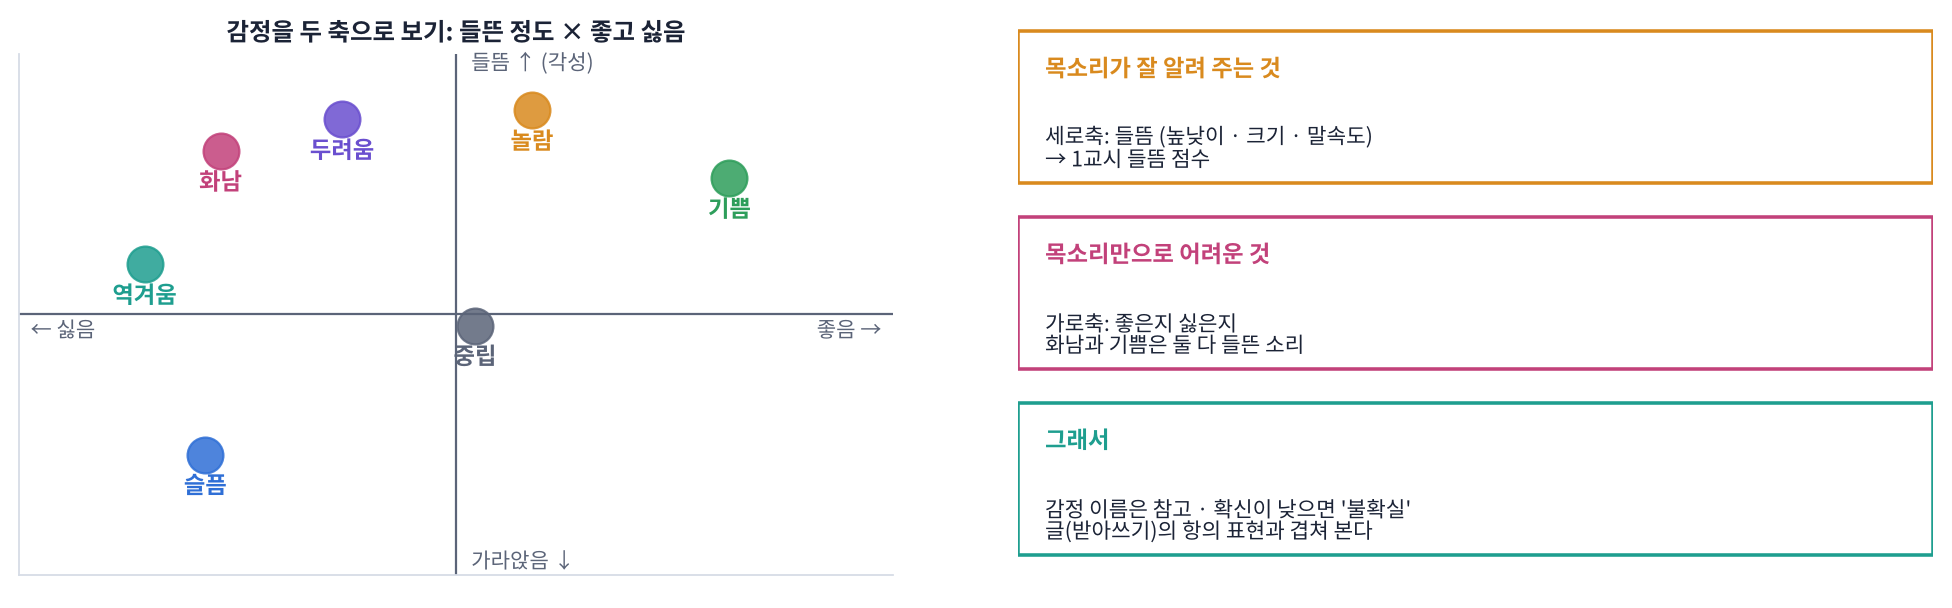

| 알아 둘 것 | 내용 |
|---|---|
| **학습 데이터** | 대부분 배우가 **연기한** 감정입니다. 실제 통화의 감정은 훨씬 약하고 섞여 있습니다 |
| **이름 붙이기의 한계** | 사람끼리도 같은 소리에 다른 감정 이름을 붙입니다. '정답' 자체가 흔들립니다 |
| **언어 · 문화** | 화를 내는 방식은 언어 · 사람마다 다릅니다. 영어 연기 음성 성적이 한국어 통화 성적은 아닙니다 |
| **목소리 vs 글** | 이 모델은 **목소리만** 듣습니다. 차분한 목소리로 한 항의는 '중립'으로 나올 수 있습니다 |

> 💬 **쉽게 말하면**: 감정 모델의 답은 '이 소리는 배우가 화난 연기를 할 때의 소리와 닮았다'는 뜻입니다. '이 사람이 화났다'와 같은 말이 아닙니다.

> 🍎 **비유**: 연극을 많이 본 사람이 전화 목소리만 듣고 기분을 짐작하는 것과 같습니다. 과장된 연기는 잘 맞히지만, 속으로 삭이는 사람의 마음은 맞히지 못합니다.

> 🎬 **애니메이션 D36-4:** [감정과 확신](https://imguru-mooc.github.io/AI_Voice/day36/animation.html#emotion) — 확신이 낮은 답을 '불확실'로 돌릴 때 정확도와 답하는 비율이 맞바뀌는 모습

In [ ]:
# 🧠 감정 인식 모델 불러오기 (emotion2vec+ base, 약 360 MB · 실패하면 transformers의 예비 모델로)
EMO_KO = {"angry": "화남", "disgusted": "역겨움", "fearful": "두려움", "happy": "기쁨", "neutral": "중립", "other": "기타", "sad": "슬픔", "surprised": "놀람", "unknown": "모름"}
try:
    from funasr import AutoModel
    emo_model = AutoModel(model="iic/emotion2vec_plus_base", hub="hf", disable_update=True, device=DEVICE)
    EMO_BACKEND = "emotion2vec+ base (9가지 감정)"
except Exception as e:
    print(f"⚠️ emotion2vec+를 불러오지 못함 → 예비 모델로 ({type(e).__name__}: {str(e)[:80]})")
    emo_pipe = pipeline("audio-classification", model="superb/wav2vec2-base-superb-er", device=0 if GPU else -1)
    EMO_BACKEND = "wav2vec2 superb-er (예비 · 4가지 감정 · 영어 IEMOCAP으로 학습)"
print("감정 모델:", EMO_BACKEND)

In [ ]:
# ⭐ 핵심 코드: 소리 → {감정: 확률}
def emotion(y):
    y = to_np(y)
    if EMO_BACKEND.startswith("emotion2vec"):
        fd, path = tempfile.mkstemp(suffix=".wav"); os.close(fd); sf.write(path, y, SR)
        try:
            r = emo_model.generate(path, granularity="utterance", extract_embedding=False, disable_pbar=True)[0]   # ⭐ 발화 전체에 감정 하나
        finally:
            os.remove(path)
        name = lambda lab: "unknown" if "unk" in lab else lab.split("/")[-1]      # 라벨이 '生气/angry' 모양이라 뒤쪽 영어만
        probs = {name(lab): float(s) for lab, s in zip(r["labels"], r["scores"])}
    else:
        short = {"neu": "neutral", "hap": "happy", "ang": "angry", "sad": "sad"}
        probs = {short.get(d["label"], d["label"]): float(d["score"]) for d in emo_pipe({"raw": y, "sampling_rate": SR}, top_k=None)}
    return dict(sorted(probs.items(), key=lambda kv: -kv[1]))                     # ⭐ 확률이 큰 순서로

p = emotion(SAY["차분"])
print("차분한 합성 음성 →", {EMO_KO.get(k, k): round(v, 3) for k, v in list(p.items())[:4]})
if len(ACT):
    r = ACT[ACT.emo == "angry"].iloc[0]; q = emotion(r.wav)
    play(r.wav, SR, "배우의 화난 연기"); print("화난 연기 →", {EMO_KO.get(k, k): round(v, 3) for k, v in list(q.items())[:4]})
verify(abs(sum(p.values()) - 1) < 0.05 and all(0 <= v <= 1 for v in p.values()), "감정별 확률이 0 ~ 1이고 모두 더하면 1")

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
r = emo_model.generate(path, granularity="utterance", extract_embedding=False, disable_pbar=True)[0]
return dict(sorted(probs.items(), key=lambda kv: -kv[1]))
```

**해설**: `granularity="utterance"`는 소리 전체를 듣고 감정을 **하나** 고르라는 뜻입니다(`"frame"`이면 조각마다 특징을 돌려줌). `extract_embedding=False`는 감정 확률만 받고 임베딩은 받지 않겠다는 뜻입니다. 결과의 `labels`와 `scores`를 짝지어 사전으로 만들고 확률이 큰 순서로 정렬합니다. 확률을 모두 더하면 1입니다. 그래서 **어떤 소리를 넣어도 무언가는 가장 높게** 나옵니다. 기침 소리나 음악을 넣어도 감정 하나가 1등이 됩니다. 1등의 확률이 낮으면 '모르겠다'고 말할 장치가 필요합니다(직접 작성 2).

</details>

In [ ]:
# 🧪 감정 모델 시험: 배우가 연기한 감정 6가지 (영어 · CREMA-D) → 혼동표
if len(ACT):
    ACT["probs"] = [emotion(y) for y in ACT.wav]                                 # T4 약 20초
    ACT["pred"] = ACT.probs.map(lambda p: next(iter(p)))                         # 확률이 가장 큰 감정
    ACT["conf"] = ACT.probs.map(lambda p: next(iter(p.values())))
    cm = pd.crosstab(ACT.emo.map(EMO_KO), ACT.pred.map(lambda e: EMO_KO.get(e, e)), rownames=["연기한 감정"], colnames=["모델의 답"])
    display(cm)
    print(f"맞힌 비율 {np.mean(ACT.emo == ACT.pred):.1%} ({len(ACT)}개) · 감정별:", {EMO_KO[e]: f"{np.mean(g.emo == g.pred):.0%}" for e, g in ACT.groupby("emo")})
    print(f"맞혔을 때 평균 확신 {ACT.conf[ACT.emo == ACT.pred].mean():.2f} · 틀렸을 때 {ACT.conf[ACT.emo != ACT.pred].mean() if (ACT.emo != ACT.pred).any() else float('nan'):.2f}")
else:
    print("연기 음성을 내려받지 못해 건너뜁니다.")

**❓ 생각해 보기**: 혼동표에서 가장 많이 헷갈린 감정 쌍은 무엇인가요? 그리고 이 성적을 '한빛치과 통화에서도 이만큼 맞힌다'고 말해도 될까요?

<details>
<summary>답 보기</summary>

흔히 **두려움 ↔ 슬픔**, **역겨움 ↔ 화남 · 중립**이 섞입니다. 목소리의 들뜬 정도(각성)가 비슷한 감정끼리는 소리만으로 가르기 어렵기 때문입니다. 그리고 이 성적은 ① **영어**, ② **배우의 연기**, ③ **조용한 녹음실**, ④ 정해진 **두 문장**에서의 성적입니다. 한국어 전화 통화는 넷 모두 다릅니다. 실제 통화에서는 감정이 약하고, 전화 음질이며, 사람이 붙인 정답조차 서로 다릅니다. 서비스에 쓰려면 **우리 통화에 사람이 표시한 표본**으로 다시 재야 하고, 그때도 '참고 신호'로만 씁니다.

</details>

In [ ]:
# ✍️ 직접 작성 2 (2교시): 확신이 낮으면 '불확실'이라고 답하는 판정 함수
# probs는 {감정: 확률} 사전입니다. 확률이 가장 큰 감정의 이름을 돌려주되,
# 그 확률이 min_conf보다 작으면 "불확실"을 돌려주는 함수를 직접 작성하세요. (2 ~ 3줄)
def decide(probs, min_conf=0.6):
    ...                                                  # ← 이 줄을 지우고 작성하세요

if practice(lambda: [decide({"angry": 0.7, "sad": 0.2, "neutral": 0.1}), decide({"angry": 0.45, "sad": 0.4, "neutral": 0.15}),
                     decide({"sad": 0.3, "happy": 0.62, "neutral": 0.08}, 0.6), decide({"neutral": 0.55, "sad": 0.45}, 0.5), decide({"neutral": 0.6, "sad": 0.4}, 0.6)],
            ["angry", "불확실", "happy", "neutral", "neutral"]) and len(ACT):
    rows = []
    for th in [0.0, 0.5, 0.7, 0.9]:
        pred = ACT.probs.map(lambda p: decide(p, th)); said = pred != "불확실"
        rows.append({"확신 문턱": th, "답한 비율": f"{said.mean():.0%}", "답한 것 중 맞힌 비율": f"{np.mean(pred[said] == ACT.emo[said]):.0%}" if said.any() else "-"})
    display(pd.DataFrame(rows))

<details>
<summary><b>💡 힌트 보기 (클릭)</b></summary>

1. 가장 큰 확률의 감정 이름은 D35에서 쓴 방법 그대로입니다: `max(probs, key=probs.get)`.
2. 그 감정의 확률은 `probs[이름]`입니다. 이 값을 `min_conf`와 비교합니다.
3. 작으면 `"불확실"`, 아니면 이름을 돌려줍니다. 경계(`0.6`과 `0.6`)는 통과시키세요: `<`를 씁니다.

</details>

<details>
<summary><b>🔑 정답 보기 (클릭)</b></summary>

```python
def decide(probs, min_conf=0.6):
    best = max(probs, key=probs.get)
    return best if probs[best] >= min_conf else "불확실"
```

**해설**: 모델은 늘 무언가를 1등으로 내놓지만, 1등의 확률이 낮다는 것은 **모델 스스로도 헷갈린다**는 신호입니다. 그때 '불확실'로 답을 미루면 **답하는 비율은 줄고 답한 것의 정확도는 오릅니다**(아래 표). D35에서 문턱 하나가 FAR과 FRR을 맞바꾼 것과 같은 구조입니다. 통화 분석에서는 '불확실'을 **중립으로 치지 않고** 따로 셉니다. '모른다'와 '평온하다'는 다른 정보이기 때문입니다.

</details>

### 2-1. 목소리의 감정과 글의 감정은 다르다

같은 항의 문장을 **차분한 목소리**와 **큰 소리**로 합성해 감정 모델에 들려줍니다. 글자는 똑같이 화가 나 있습니다.

In [ ]:
# 🧪 화난 '글' + 차분한 '목소리'
ANGRY_TEXT = "지금 세 번째 전화하는 건데 왜 아직도 처리가 안 됐어요?"
rows = []
for style in ["차분", "큰 소리"]:
    y = act(ANGRY_TEXT, style); p = emotion(y); f = prosody(y, ANGRY_TEXT)
    play(y, SR, f"{style}: {ANGRY_TEXT}")
    rows.append({"말투": style, "받아쓰기": stt(y), "감정 모델 1등": EMO_KO.get(next(iter(p)), next(iter(p))), "확신": round(next(iter(p.values())), 2),
                 "말속도": round(f["말속도(음절/초)"], 1), "높낮이(Hz)": round(f["높낮이(Hz)"])})
display(pd.DataFrame(rows))
print("받아쓰기는 두 줄이 같습니다. 글자에 '세 번째 · 왜 아직도'가 있어도 감정 모델은 글자를 읽지 않고 목소리만 듣습니다.")

**❓ 생각해 보기**: 합성 음성(TTS)에 대한 감정 모델의 답을 믿어도 될까요? 그리고 통화 분석에서 '글'과 '목소리' 가운데 무엇을 써야 할까요?

<details>
<summary>답 보기</summary>

TTS는 감정 없이 글자를 읽으므로 대부분 **중립**이나 낮은 확신으로 나옵니다. 빠르기 · 높이만 바꾼 '말투 흉내'는 사람의 감정 표현과 다르기 때문에, 오늘 합성 통화에서 감정 모델 칸은 **참고용**으로만 둡니다. 실제 통화 분석에서는 **둘 다** 씁니다. 글(받아쓰기)에서는 '세 번째 전화 · 책임자 · 환불' 같은 **항의 표현**을, 목소리에서는 **들뜸 · 감정**을 따로 뽑아 겹칩니다. 글은 차분한 항의를 잡고, 목소리는 말로 표현하지 않은 다급함을 잡습니다. 한쪽만 쓰면 다른 쪽을 놓칩니다.

</details>

### 2-2. 감정 타임라인: 긴 녹음을 창으로 잘라 보기

통화 전체에 감정 이름 하나를 붙이면 '처음엔 차분했다가 나중에 화남'을 알 수 없습니다. **짧은 창을 옮겨 가며** 감정을 재고, 창마다 튀는 값을 **이동 평균**으로 다듬습니다.

👣 **한 단계씩**: 2.5초 창을 0.5초씩 옮김 → 창마다 감정 확률 → 앞뒤 창과 평균 → 시간에 따른 곡선

> 🎬 **애니메이션 D36-5:** [타임라인 다듬기](https://imguru-mooc.github.io/AI_Voice/day36/animation.html#timeline) — 창 길이와 이동 평균 폭에 따라 튀는 값이 줄고 반응이 늦어지는 모습

In [ ]:
# ⭐ 핵심 코드: 창으로 잘라 감정 타임라인 만들기 + 이동 평균
def windows(y, win=2.5, hop=0.5, sr=SR):                 # [(시작 시각, 조각), ...]
    n, h = int(win * sr), int(hop * sr)
    return [(i / sr, y[i:i + n]) for i in range(0, max(1, len(y) - n + 1), h)]    # ⭐ 창을 hop만큼씩 옮김

def smooth(P, k=3):                                      # 열마다 앞뒤 k개 창의 평균
    ker = np.ones(k) / k
    return np.stack([np.convolve(P[:, j], ker, mode="same") for j in range(P.shape[1])], axis=1)   # ⭐ 이동 평균

if len(ACT):
    a0 = ACT[ACT.actor == ACT.actor.iloc[0]]              # 배우 한 명의 연기를 이어 붙여 '감정이 바뀌는 녹음'을 만듦
    order = [("neutral", "ITS"), ("neutral", "DFA"), ("sad", "ITS"), ("angry", "ITS"), ("angry", "DFA"), ("happy", "ITS")]
    parts, truth, t = [], [], 0.0
    for emo, sent in order:
        sel = a0[(a0.emo == emo) & (a0.sent == sent)]
        if len(sel):
            y = np.r_[sel.wav.iloc[0], silence(0.3)]; parts.append(y); truth.append((t, t + len(y) / SR, emo)); t += len(y) / SR
    LONG = np.concatenate(parts); play(LONG, SR, "배우 한 명의 연기 이어 붙이기: " + " → ".join(EMO_KO[e] for _, _, e in truth))
    W = windows(LONG); SHOW = ["neutral", "sad", "angry", "happy"]
    P = np.array([[emotion(w).get(e, 0.0) for e in SHOW] for _, w in W]); Ps = smooth(P, 3)
    tt = np.array([s + 1.25 for s, _ in W])              # 창의 가운데 시각
    fig, ax = plt.subplots(2, 1, figsize=(12, 4.6), sharex=True)
    for a_, M, title in [(ax[0], P, "raw (window by window)"), (ax[1], Ps, "smoothed (moving average of 3 windows)")]:
        for j, (e, col) in enumerate(zip(SHOW, ["#7B8496", "#2B78D6", "#D0453B", "#D98A1E"])): a_.plot(tt, M[:, j], color=col, label=e)
        for s, e_, emo in truth: a_.axvspan(s, e_, color={"neutral": "#7B8496", "sad": "#2B78D6", "angry": "#D0453B", "happy": "#D98A1E"}[emo], alpha=0.08)
        a_.set_ylim(0, 1); a_.set_ylabel("probability"); a_.set_title(title, fontsize=10)
    ax[0].legend(fontsize=8, ncol=4); ax[1].set_xlabel("time (s) · shaded = acted emotion"); plt.tight_layout(); plt.show()
    flips = lambda M: int(np.sum(np.diff(M.argmax(axis=1)) != 0))
    print(f"창 {len(W)}개 · 1등 감정이 바뀐 횟수: 다듬기 전 {flips(P)}번 → 다듬은 뒤 {flips(Ps)}번 (실제 변화 {len(truth) - 1 - sum(truth[i][2] == truth[i + 1][2] for i in range(len(truth) - 1))}번)")
    verify(P.shape == Ps.shape == (len(W), 4) and Ps.max() <= P.max() + 1e-9, "창 개수만큼 줄이 있고, 다듬은 값의 최댓값은 원래보다 크지 않음")
else:
    print("연기 음성을 내려받지 못해 건너뜁니다.")

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
return [(i / sr, y[i:i + n]) for i in range(0, max(1, len(y) - n + 1), h)]
np.convolve(P[:, j], ker, mode="same")
```

**해설**: 창 길이(`win`)가 짧으면 변화를 빨리 잡지만 한 창에 담긴 소리가 적어 답이 흔들리고, 길면 안정되지만 감정이 바뀐 **경계에서 두 감정이 섞입니다.** `hop`은 창을 옮기는 간격으로, 작을수록 곡선이 촘촘해지지만 계산이 늘어납니다. 이동 평균(`np.convolve`에 `1/k`짜리 막대)은 앞뒤 창의 값을 평균해 **한 창만 튄 답**을 눌러 줍니다. 대신 진짜 변화도 `k`개 창만큼 **늦게** 보입니다. 실시간 에스컬레이션에서는 이 '안정 vs 반응 속도'의 맞바꿈을 정해야 합니다. `mode="same"`은 결과 길이를 입력과 같게 유지합니다(양 끝은 값이 조금 작게 나옴).

</details>

> ⏸️ **2교시 끝.** 🎬 D36-4의 확신 문턱 슬라이더와 D36-5의 **▶ 시연 보기**를 돌려 보세요.

## Part 3. 소리 이벤트: 말이 아닌 소리 듣기  ·  3교시

통화에는 말만 있지 않습니다. 기침, 아기 울음, 유리 깨지는 소리, 사이렌 같은 **주변 소리**가 상황을 알려 줍니다. 소리 이벤트를 알아내는 방법은 두 가지입니다.

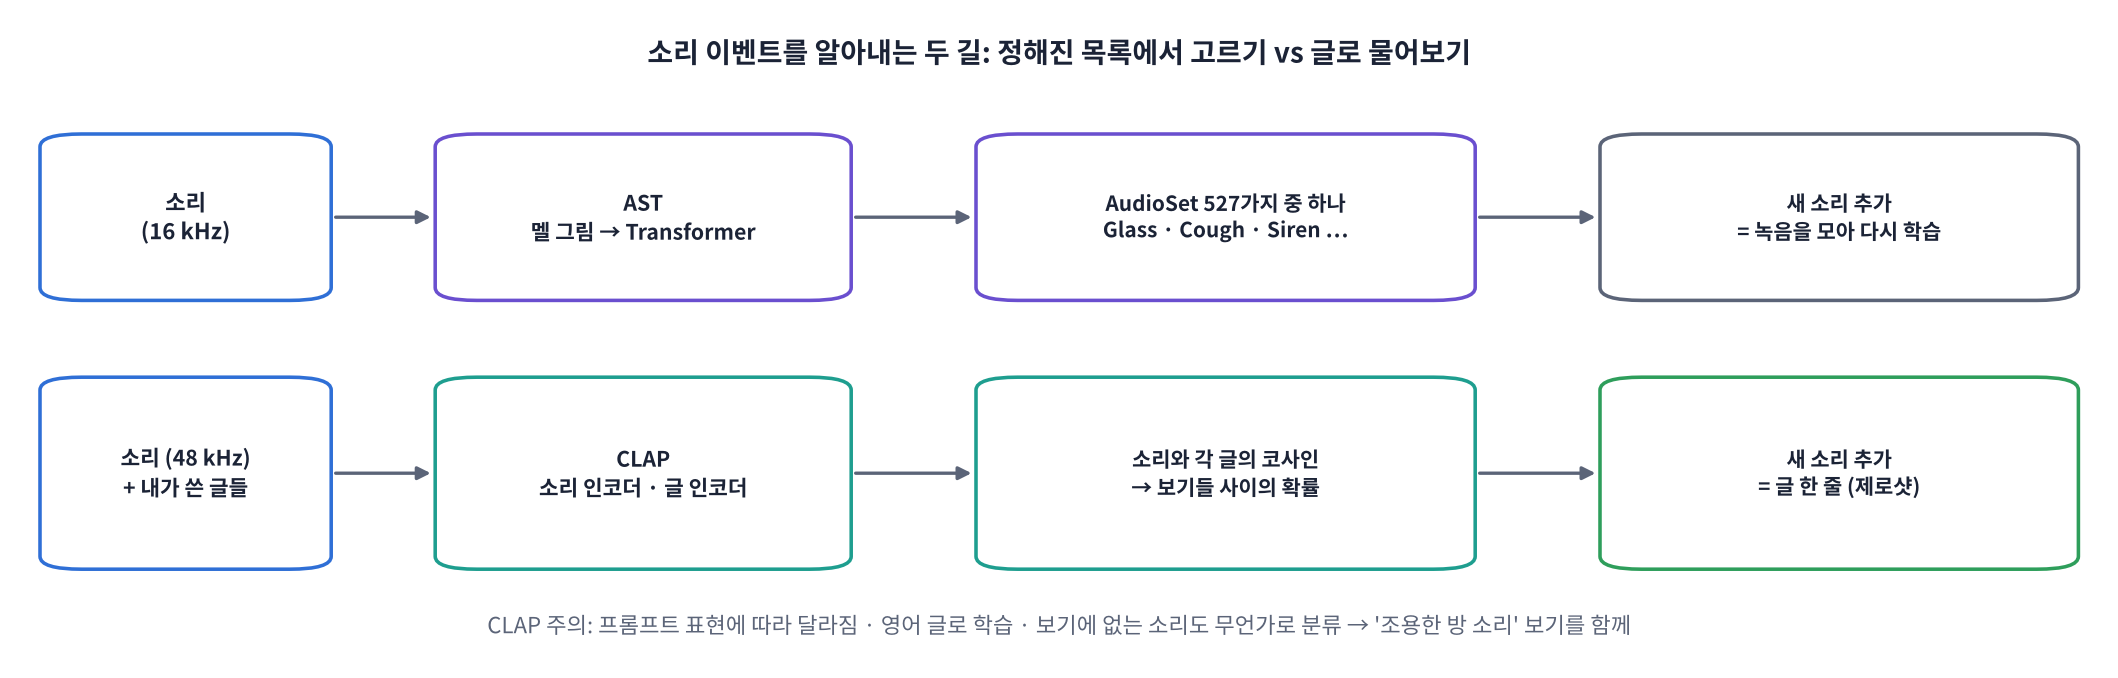

| | **AST** (Audio Spectrogram Transformer) | **CLAP** (소리 · 글 대조 학습) |
|---|---|---|
| 방식 | 미리 정해진 **527가지 목록**(AudioSet) 중에서 고름 | 소리와 **글**을 같은 공간에 놓고, 가장 가까운 글을 고름 |
| 새 소리 추가 | 다시 학습해야 함 | **글만 새로 쓰면 됨** (제로샷) |
| 장점 | 목록 안의 소리는 안정적 | 목록에 없는 소리도 물어볼 수 있음 |
| 주의 | 목록에 없으면 엉뚱한 답 | 글(프롬프트)을 어떻게 쓰느냐에 따라 답이 달라짐 |

> 💬 **쉽게 말하면**: AST는 보기가 정해진 객관식, CLAP은 보기를 내가 써서 내는 객관식입니다.

> 🍎 **비유**: AST는 **새 도감**(실려 있는 527종 가운데 고르기), CLAP은 "이 소리, **'유리 깨지는 소리'** 라는 말과 어울려요?"라고 물어볼 수 있는 친구입니다. D35에서 목소리끼리 코사인으로 비교했듯이, CLAP은 **소리와 문장**을 코사인으로 비교합니다.

> 🎬 **애니메이션 D36-6:** [AST와 CLAP](https://imguru-mooc.github.io/AI_Voice/day36/animation.html#events) — 같은 소리를 정해진 목록으로 고를 때와 글로 물어볼 때, 프롬프트에 따라 점수가 달라지는 모습

In [ ]:
# ⭐ 핵심 코드: 두 가지 소리 분류기 (AST 약 350 MB · CLAP 약 600 MB, 처음 내려받기 1 ~ 2분)
ast = pipeline("audio-classification", model="MIT/ast-finetuned-audioset-10-10-0.4593", device=0 if GPU else -1)
clap = pipeline("zero-shot-audio-classification", model="laion/clap-htsat-unfused", device=0 if GPU else -1)

def ast_top(y, k=5):                                     # 16 kHz 소리 → AudioSet 527가지 중 위에서 k개
    return [(d["label"], round(float(d["score"]), 3)) for d in ast({"raw": to_np(y), "sampling_rate": SR}, top_k=k)]   # ⭐ 정해진 목록에서 고름

def zero_shot(y48, labels, template="the sound of {}"):  # 48 kHz 소리 + 내가 쓴 글 목록 → {글: 확률}
    out = clap(to_np(y48), candidate_labels=list(labels), hypothesis_template=template)                                # ⭐ 글과 소리의 닮은 정도
    return {d["label"]: float(d["score"]) for d in out}

PROMPT = {"glass_breaking": "glass breaking", "coughing": "a person coughing", "crying_baby": "a baby crying", "siren": "a siren",
          "door_wood_knock": "knocking on a door", "dog": "a dog barking", "sneezing": "a person sneezing", "footsteps": "footsteps"}
r = ESC.iloc[0]; play(r.wav, SR, f"생활 소리: {r.ko}")
print("AST   :", ast_top(r.wav))
z = zero_shot(r.wav48, [PROMPT[c] for c in CATS]); print("CLAP  :", {k: round(v, 3) for k, v in sorted(z.items(), key=lambda kv: -kv[1])[:3]})
verify(len(ast_top(r.wav, 5)) == 5 and abs(sum(z.values()) - 1) < 0.05, "AST는 위에서 5개를 돌려주고, CLAP 확률은 내가 준 글들 사이에서 더하면 1")

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
ast({"raw": to_np(y), "sampling_rate": SR}, top_k=k)
clap(to_np(y48), candidate_labels=list(labels), hypothesis_template=template)
```

**해설**: AST는 소리를 멜 스펙트로그램 **그림**으로 바꾼 뒤 그림을 조각내 Transformer에 넣는 모델입니다(D5의 CNN 분류를 Transformer로 바꾼 것). 답은 늘 AudioSet의 527가지 이름 중 하나입니다. CLAP은 소리 인코더와 글 인코더를 **짝이 맞는 소리 · 설명글이 가까워지도록** 함께 학습했습니다. `candidate_labels`의 각 글을 `hypothesis_template`의 `{}` 자리에 넣어 문장을 만들고(`the sound of glass breaking`), 소리와 각 문장의 닮은 정도를 **주어진 글들 사이에서만** 확률로 바꿉니다. 그래서 CLAP 확률은 '보기 중에서 고르면'이라는 조건부 값입니다. 보기에 정답이 없어도 무언가는 1등이 됩니다. CLAP은 48 kHz 소리로 학습했기 때문에 16 kHz로 낮춘 소리를 넣으면 높은 주파수(유리 · 금속 소리)의 단서를 잃습니다.

</details>

In [ ]:
# 🧪 두 분류기 시험: 생활 소리 (ESC-50) — AST는 목록 이름에 핵심 낱말이 들어 있으면 맞힌 것으로 셈 (T4 약 30초)
AST_KEYS = {"glass_breaking": ["glass", "shatter", "breaking"], "coughing": ["cough"], "crying_baby": ["baby cry", "crying"], "siren": ["siren"],
            "door_wood_knock": ["knock"], "dog": ["dog", "bark"], "sneezing": ["sneeze"], "footsteps": ["footsteps", "walk"]}
hit = lambda labels, cat: any(k in lab.lower() for lab in labels for k in AST_KEYS[cat])
ESC["ast"] = [[l for l, _ in ast_top(y, 5)] for y in ESC.wav]
ESC["clap"] = [zero_shot(y, [PROMPT[c] for c in CATS]) for y in ESC.wav48]
ESC["clap_pred"] = ESC.clap.map(lambda z: max(z, key=z.get))
tab = pd.DataFrame({"AST 1등이 맞음": ESC.apply(lambda r: hit(r["ast"][:1], r["cat"]), axis=1), "AST 5등 안에 있음": ESC.apply(lambda r: hit(r["ast"], r["cat"]), axis=1),
                    "CLAP 1등이 맞음": ESC.clap_pred == ESC.cat.map(PROMPT)}).groupby(ESC.ko, sort=False).mean()
tab.loc["전체"] = tab.mean(); display(tab.round(2))
miss = ESC[ESC.clap_pred != ESC.cat.map(PROMPT)]
if len(miss): print("CLAP이 틀린 예:", [(r.ko, "→", r.clap_pred) for r in miss.head(4).itertuples()])

In [ ]:
# 🧪 프롬프트 실험: 같은 소리, 글만 바꿔서 (CLAP의 글 인코더는 영어로 학습됨)
ONE = {"glass_breaking": "glass", "coughing": "cough", "crying_baby": "baby", "siren": "siren", "door_wood_knock": "door", "dog": "dog", "sneezing": "sneeze", "footsteps": "steps"}
KO = {"glass_breaking": "유리 깨지는 소리", "coughing": "기침 소리", "crying_baby": "아기 우는 소리", "siren": "사이렌 소리", "door_wood_knock": "문 두드리는 소리",
      "dog": "개 짖는 소리", "sneezing": "재채기 소리", "footsteps": "발소리"}
rows = []
for name, table, tpl in [("영어 구절 + 'the sound of …'", PROMPT, "the sound of {}"), ("영어 한 낱말", ONE, "{}"), ("한국어", KO, "{}")]:
    pred = [max(z := zero_shot(y, [table[c] for c in CATS], tpl), key=z.get) for y in ESC.wav48]
    rows.append({"프롬프트": name, "예": table[CATS[0]], "맞힌 비율": f"{np.mean([p == table[c] for p, c in zip(pred, ESC.cat)]):.0%}"})
display(pd.DataFrame(rows))

# 보기에 없던 소리를 글만 더해서 물어보기: 경보기 삑삑 소리를 직접 만들어 들려줌
t = np.arange(4 * SR48) / SR48
alarm = (0.3 * np.sin(2 * np.pi * 3100 * t) * (np.floor(t * 2) % 2 == 0)).astype(np.float32)
play(librosa.resample(alarm, orig_sr=SR48, target_sr=SR), SR, "만든 소리: 경보기")
z = zero_shot(alarm, [PROMPT[c] for c in CATS] + ["a smoke alarm beeping", "a person screaming"])
print("새 보기 두 개를 더해 물어본 결과:", {k: round(v, 3) for k, v in sorted(z.items(), key=lambda kv: -kv[1])[:3]})

**❓ 생각해 보기**: AST가 **목록에 없는 소리**(예: 우리 병원의 진료 호출 벨)를 새로 알아듣게 하려면 무엇이 필요하고, CLAP에서는 보기를 더할 때 무엇이 필요했나요? 그렇다면 CLAP만 쓰면 될까요?

<details>
<summary>답 보기</summary>

AST는 목록에 없는 소리를 추가하려면 **그 소리의 녹음을 모아 다시 학습**해야 합니다. CLAP은 **글 한 줄**을 보기에 더했을 뿐입니다. 이것이 제로샷의 힘입니다. 하지만 CLAP은 ① 프롬프트 표현에 따라 답이 흔들리고(위 표), ② 한국어 글은 잘 알아듣지 못하며, ③ 확률이 '보기 중에서'의 값이라 **보기에 없는 소리도 무언가로 분류**합니다. 그래서 실무에서는 '조용한 방 소리' · '사람 말소리' 같은 **배경 보기**를 꼭 넣고, 놓치면 안 되는 소리(비명 · 경보)는 그 소리의 녹음으로 **문턱을 따로 맞추거나** 전용 분류기를 둡니다. 새 요구를 빨리 시험할 때는 CLAP, 굳어진 요구는 전용 모델이 흔한 조합입니다.

</details>

### 3-1. 긴 녹음에서 '언제' 났는지 찾기

분류기는 "이 5초가 무슨 소리인가"에 답합니다. 통화에서는 **언제부터 언제까지** 났는지가 필요합니다. 2교시와 같은 방법으로 창을 옮겨 가며 묻고, 문턱을 넘은 창이 이어지면 **하나의 구간**으로 묶습니다.

👣 **한 단계씩**: 2초 창을 1초씩 옮김 → 창마다 CLAP에 묻기(보기에 '조용한 방 소리' · '사람 말소리' 포함) → 확률 ≥ 문턱인 창 표시 → 이어진 창을 구간으로

> 🎬 **애니메이션 D36-7:** [이벤트 구간 찾기](https://imguru-mooc.github.io/AI_Voice/day36/animation.html#detect) — 문턱을 올리고 내릴 때 놓침과 오경보가 맞바뀌고, 이어진 창이 구간으로 묶이는 모습

In [ ]:
# ⭐ 핵심 코드: 긴 녹음에서 이벤트 구간 찾기
DET_TH, DET_WIN, DET_HOP = 0.5, 2.0, 1.0                 # ✏️ 문턱 · 창 길이 · 옮기는 간격(초)
OTHERS = ["quiet room noise", "a person talking"]         # ⭐ 찾는 소리가 아닌 것들: 조용한 방 · 사람 말소리

def segments(times, flags, win):                         # 켜진 창이 이어지면 하나의 (시작, 끝) 구간으로
    segs, start, prev = [], None, None
    for t, f in zip(times, flags):
        if f and start is None: start = t                # ⭐ 꺼짐 → 켜짐: 구간 시작
        if not f and start is not None: segs.append((start, prev + win)); start = None   # ⭐ 켜짐 → 꺼짐: 구간 끝
        prev = t
    if start is not None: segs.append((start, prev + win))
    return segs

def detect(y48, cats, th=None):                          # → [(시작, 끝, 소리 종류), ...]
    th = DET_TH if th is None else th
    W = windows(y48, DET_WIN, DET_HOP, SR48); times = [s for s, _ in W]
    Z = [zero_shot(w, [PROMPT[c] for c in cats] + OTHERS) for _, w in W]
    found = []
    for c in cats:
        for s, e in segments(times, [z[PROMPT[c]] >= th for z in Z], DET_WIN): found.append((s, e, c))
    return sorted(found), times, Z

def trimmed(y48, max_sec=3.0):                           # 앞뒤 조용한 부분을 잘라낸 이벤트 소리
    y, _ = librosa.effects.trim(y48, top_db=35); return y[:int(max_sec * SR48)]

rng = np.random.default_rng(3)
STREAM = (rng.standard_normal(32 * SR48) * 10 ** (-52 / 20)).astype(np.float32)        # 32초짜리 조용한 방
PLAN = [c for c in ["coughing", "door_wood_knock", "glass_breaking", "crying_baby", "siren"] if c in CATS][:4]
TRUTH = []
for k, c in enumerate(PLAN):
    y = trimmed(ESC[ESC.cat == c].wav48.iloc[1]); s = 3.0 + 7.5 * k
    STREAM[int(s * SR48):int(s * SR48) + len(y)] += y; TRUTH.append((s, s + len(y) / SR48, c))
play(librosa.resample(STREAM, orig_sr=SR48, target_sr=SR), SR, "32초 녹음: " + " · ".join(EVENTS[c] for c in PLAN))
FOUND, T_DET, Z_DET = detect(STREAM, PLAN)
fig, ax = plt.subplots(figsize=(12, 3))
for j, c in enumerate(PLAN): ax.plot(np.array(T_DET) + DET_WIN / 2, [z[PROMPT[c]] for z in Z_DET], label=PROMPT[c])
ax.axhline(DET_TH, color="k", ls="--", lw=1)
for s, e, c in TRUTH: ax.axvspan(s, e, color="#D98A1E", alpha=0.15)
ax.set_xlabel("time (s) · shaded = where the event really is"); ax.set_ylabel("CLAP probability"); ax.legend(fontsize=8, ncol=4); ax.set_title("sliding-window zero-shot detection", fontsize=10)
plt.tight_layout(); plt.show()
display(pd.DataFrame([{"찾은 소리": EVENTS[c], "시작(초)": s, "끝(초)": e} for s, e, c in FOUND]) if FOUND else "찾은 구간이 없습니다 (문턱을 낮춰 보세요)")
verify(all(e > s for s, e, _ in FOUND) and len(Z_DET) == len(T_DET), "찾은 구간마다 끝이 시작보다 뒤이고, 창마다 확률이 하나씩 있음")

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
if f and start is None: start = t
if not f and start is not None: segs.append((start, prev + win)); start = None
```

**해설**: 창마다 '문턱을 넘었나(True/False)'를 줄 세운 뒤, **False → True로 바뀌는 곳이 구간의 시작**, **True → False로 바뀌는 곳이 끝**입니다. 끝 시각은 마지막으로 켜진 창의 시작(`prev`)에 창 길이를 더한 값입니다. 창이 2초라서 찾은 구간은 실제 소리보다 **앞뒤로 넓게** 나옵니다. 창을 줄이면 경계는 정확해지지만 한 창에 담긴 소리가 적어 분류가 흔들립니다. 문턱(`DET_TH`)을 낮추면 놓치는 소리가 줄고 오경보가 늘며, 올리면 반대입니다. `OTHERS`의 두 보기(`quiet room noise` · `a person talking`)가 중요합니다. CLAP 확률은 보기들 사이에서만 나누므로, 이 둘을 넣지 않으면 조용한 창과 **사람이 말하는 창**도 기침 · 유리 같은 보기 중 하나로 분류되어 오경보가 쏟아집니다. 통화에서는 대부분의 시간이 말소리입니다.

</details>

In [ ]:
# ✍️ 직접 작성 3 (3교시): 두 구간이 겹치는 시간(초)을 돌려주는 함수
# a와 b는 (시작, 끝) 튜플입니다. 두 구간이 겹치는 길이를 초로 돌려주고, 겹치지 않으면 0을 돌려주는 함수를 직접 작성하세요. (1 ~ 2줄)
def overlap(a, b):
    ...                                                  # ← 이 줄을 지우고 작성하세요

if practice(lambda: [overlap((0, 5), (3, 8)), overlap((3, 8), (0, 5)), overlap((0, 2), (5, 7)), overlap((1, 9), (4, 6)), overlap((0, 3), (3, 6))], [2, 2, 0, 2, 0]):
    rows = []
    for s, e, c in TRUTH:
        got = [f for f in FOUND if f[2] == c and overlap((s, e), f[:2]) > 0]
        rows.append({"실제 소리": EVENTS[c], "실제 구간": f"{s:.1f} ~ {e:.1f}", "찾았나": "✔" if got else "✘ 놓침", "찾은 구간": ", ".join(f"{a:.0f} ~ {b:.0f}" for a, b, _ in got) or "-"})
    display(pd.DataFrame(rows))
    false_alarm = [f for f in FOUND if not any(c == f[2] and overlap((s, e), f[:2]) > 0 for s, e, c in TRUTH)]
    print(f"놓친 소리 {sum(r['찾았나'] != '✔' for r in rows)}개 · 오경보 {len(false_alarm)}개:", [(EVENTS[c], s, e) for s, e, c in false_alarm])

<details>
<summary><b>💡 힌트 보기 (클릭)</b></summary>

1. 겹치는 부분은 '더 늦은 시작'부터 '더 이른 끝'까지입니다.
2. 더 늦은 시작은 `max(a[0], b[0])`, 더 이른 끝은 `min(a[1], b[1])`입니다. 둘을 빼면 겹친 길이입니다.
3. 겹치지 않으면 뺀 값이 음수가 됩니다. `max(0, ...)`으로 0 아래를 막으세요.

</details>

<details>
<summary><b>🔑 정답 보기 (클릭)</b></summary>

```python
def overlap(a, b):
    return max(0, min(a[1], b[1]) - max(a[0], b[0]))
```

**해설**: 두 구간의 겹침은 `[더 늦은 시작, 더 이른 끝]`입니다. `(0, 5)`와 `(3, 8)`이면 3부터 5까지 2초입니다. 떨어진 구간은 '더 이른 끝'이 '더 늦은 시작'보다 앞이라 음수가 나오므로 0으로 막습니다. 끝과 시작이 딱 붙은 `(0, 3)` · `(3, 6)`은 0입니다. 이 함수로 '찾은 구간이 실제 구간과 겹치는가'를 세면 **놓침**(실제 소리인데 겹치는 구간이 없음)과 **오경보**(찾았는데 겹치는 실제 소리가 없음)를 구할 수 있습니다. D9의 화자 분리 오류율, 물체 검출의 IoU가 모두 이 계산에서 출발합니다.

</details>

> ⏸️ **3교시 끝.** 🎬 D36-7에서 문턱을 움직이며 놓침과 오경보가 어떻게 맞바뀌는지 보세요.

## Part 4. 통화 분석 리포트와 에스컬레이션 규칙  ·  4교시

오늘 만든 세 가지 귀(**말투 · 감정 · 주변 소리**)와 받아쓰기의 **글**을 한 통화에 겹쳐 봅니다. 콜센터 녹음은 보통 **손님 채널과 상담원 채널이 따로** 저장되므로, 손님 채널만 분석합니다.

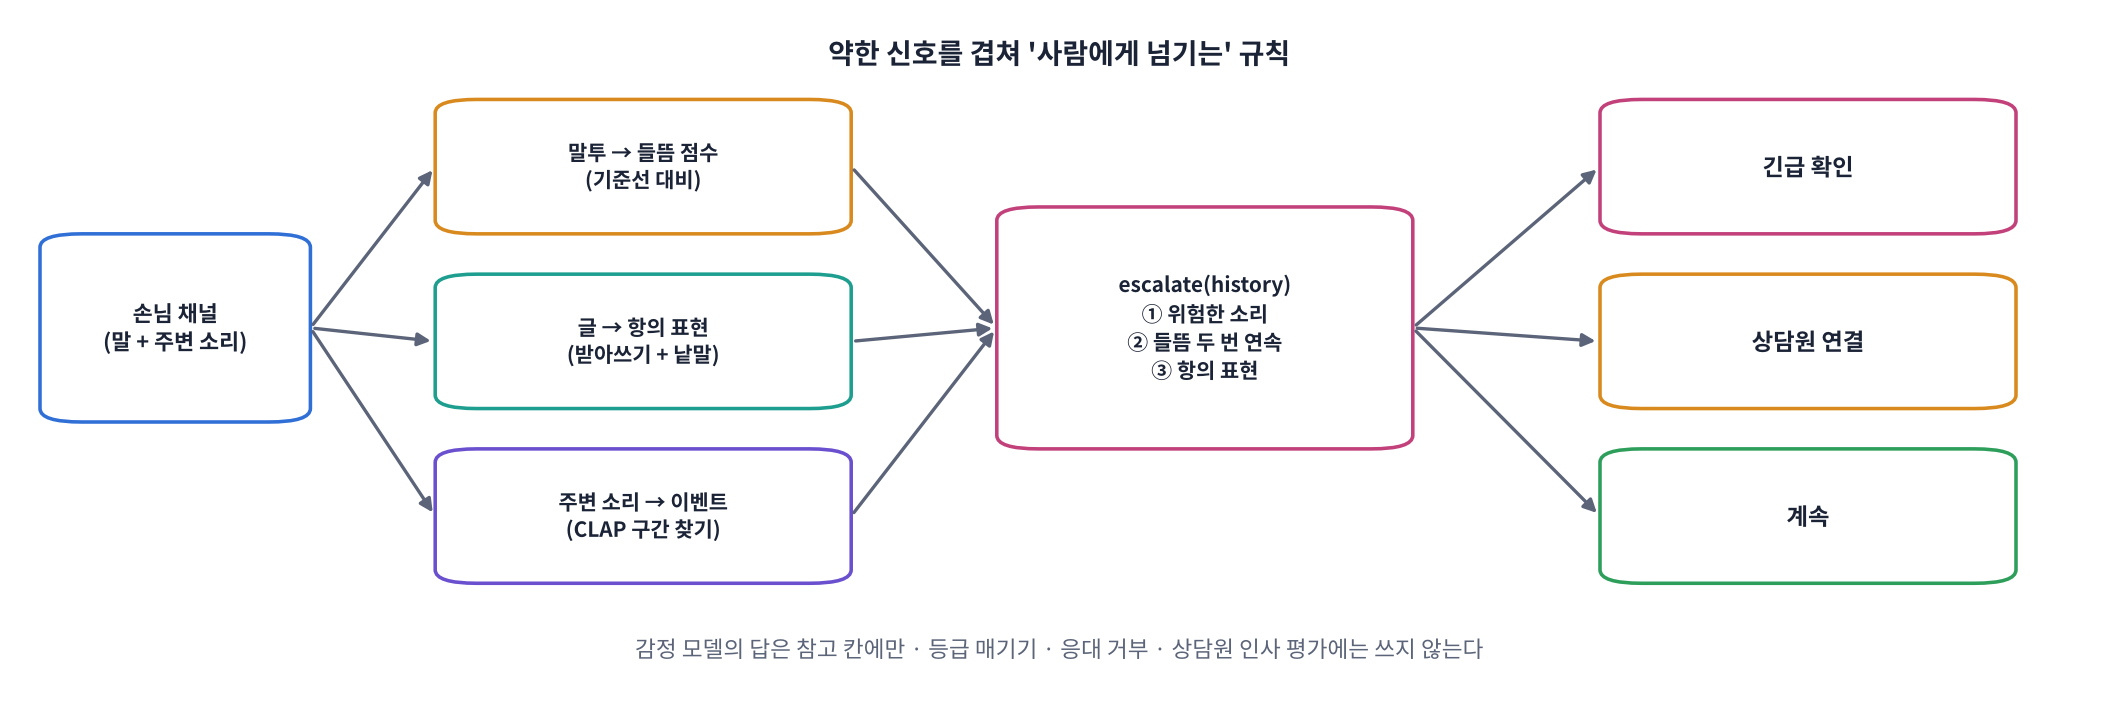

| 신호 | 어디에서 | 오늘의 함수 | 믿을 만한 정도 |
|---|---|---|---|
| **들뜸** | 말투 (기준선 대비) | `prosody` → `arousal` | 변화의 방향은 믿을 만함. 이유(화남 · 기쁨 · 급함)는 모름 |
| **항의 표현** | 글 (받아쓰기) | 낱말 목록 | 받아쓰기가 맞으면 분명함. 돌려 말하면 놓침 |
| **주변 소리** | 소리 이벤트 | `detect` (CLAP) | 큰 소리는 잘 잡음. 오경보 있음 |
| **감정 이름** | 감정 모델 | `emotion` | 연기 음성 기준. 실제 통화 · 합성 음성에서는 참고만 |

📐 **핵심 식 하나 (에스컬레이션)**: `위험한 소리 → 긴급 확인` · `들뜸이 두 번 이어짐 또는 항의 표현 → 상담원 연결` · `그 밖 → 계속`

> 💬 **쉽게 말하면**: 신호 하나로 결정하지 않습니다. 약한 신호 여러 개가 겹칠 때, 그리고 '사람에게 넘기는' 방향으로만 씁니다.

> 🎬 **애니메이션 D36-8:** [에스컬레이션 규칙](https://imguru-mooc.github.io/AI_Voice/day36/animation.html#rules) — 통화가 흘러가며 세 신호가 쌓이고, 규칙을 켜고 끌 때 넘기는 시점이 달라지는 모습

In [ ]:
# 📞 가상의 통화 만들기: 손님 채널(말 + 주변 소리)과 상담원 채널을 따로 (통화 내용은 모두 가상)
CALL = [("A", "차분", "한빛치과입니다. 무엇을 도와드릴까요?"),
        ("C", "차분", "안녕하세요. 내일 오후 세 시 예약을 확인하고 싶어요."),
        ("A", "차분", "확인해 보니 그 예약은 취소된 것으로 나옵니다."),
        ("C", "서두름", "네? 저는 취소한 적이 없는데요. 다시 확인해 주세요."),
        ("A", "차분", "죄송합니다. 다른 날짜로 다시 잡아 드릴까요?"),
        ("C", "큰 소리", "지금 두 번째 전화하는 거예요. 책임자 바꿔 주세요."),
        ("A", "차분", "불편을 드려 죄송합니다. 바로 확인하겠습니다."),
        ("C", "큰 소리", "아이가 아파서 급한데 왜 이렇게 오래 걸려요.")]
TURNS, t = [], 0.5
for who, style, text in CALL:
    y = act(text, style, VOICE_USER if who == "C" else VOICE_BOT)
    TURNS.append(dict(who=who, style=style, text=text, start=t, end=t + len(y) / SR, wav=y)); t += len(y) / SR + 0.5
CALL_SEC = t + 4.0
ch_c = (np.random.default_rng(5).standard_normal(int(CALL_SEC * SR48)) * 10 ** (-55 / 20)).astype(np.float32)   # 손님 채널 (48 kHz)
ch_a = np.zeros(int(CALL_SEC * SR), np.float32)                                                                  # 상담원 채널 (16 kHz)
for u in TURNS:
    if u["who"] == "C":
        y = librosa.resample(u["wav"], orig_sr=SR, target_sr=SR48); i = int(u["start"] * SR48); ch_c[i:i + len(y)] += y
    else:
        i = int(u["start"] * SR); ch_a[i:i + len(u["wav"])] += u["wav"]
C_TURNS = [u for u in TURNS if u["who"] == "C"]
def add_bg(cat, at, gain):                               # 손님 쪽 주변 소리를 손님 채널에 섞음
    if cat in CATS:
        y = trimmed(ESC[ESC.cat == cat].wav48.iloc[2]) * gain; i = int(at * SR48); ch_c[i:i + len(y)] += y[:len(ch_c) - i]
        return [(at, at + len(y) / SR48, cat)]
    return []
BG_TRUTH = add_bg("coughing", C_TURNS[0]["end"] + 0.6, 0.6) + add_bg("crying_baby", C_TURNS[2]["end"] + 0.4, 0.5) + add_bg("glass_breaking", C_TURNS[-1]["end"] + 0.6, 0.9)
ch_c16 = librosa.resample(ch_c, orig_sr=SR48, target_sr=SR)
play(ch_c16 + ch_a, SR, f"통화 전체 (두 채널을 합쳐 들음 · {CALL_SEC:.0f}초)"); play(ch_c16, SR, "손님 채널만")
print("손님 발화", len(C_TURNS), "개 · 손님 쪽 주변 소리:", [(EVENTS[c], round(s, 1)) for s, _, c in BG_TRUTH])

In [ ]:
# ⭐ 핵심 코드: 손님 발화마다 네 가지 신호를 한 줄로 (받아쓰기 + CLAP 포함, T4 약 1분)
COMPLAINT = ["책임자", "환불", "두 번째", "세 번째", "몇 번째", "왜 이렇게", "취소한 적", "신고", "소비자원"]   # ✏️ 항의 표현 낱말
DANGER = {"glass_breaking", "siren"}                     # ✏️ 들리면 바로 확인해야 하는 소리
EV_FOUND, _, _ = detect(ch_c, [c for c in ["coughing", "crying_baby", "glass_breaking", "siren"] if c in CATS])
SIG, HIST, base = [], [], None
for k, u in enumerate(C_TURNS):
    seg = ch_c16[int(u["start"] * SR):int(u["end"] * SR)]
    heard = stt(seg)
    txt = heard if len(re.findall("[가-힣]", heard)) >= 5 else u["text"]          # 받아쓰기가 비면 말속도 계산에는 대본 글자 수를 씀
    f = prosody(seg, txt); base = base or f                                        # ⭐ 첫 발화 = 이 손님의 기준선
    nxt = C_TURNS[k + 1]["start"] if k + 1 < len(C_TURNS) else CALL_SEC
    near = sorted({c for s, e, c in EV_FOUND if s < nxt and e > u["start"]})       # ⭐ 이 발화부터 다음 발화 전까지 들린 소리
    p = emotion(seg); top = next(iter(p))
    sig = dict(arousal=round(arousal(f, base), 2), complaint=any(w in heard for w in COMPLAINT), danger=bool(DANGER & set(near)))
    HIST.append(sig)
    SIG.append({"턴": k + 1, "시각(초)": round(u["start"], 1), "연기한 말투": u["style"], "받아쓰기": heard, "말속도": round(f["말속도(음절/초)"], 1),
                "높낮이(Hz)": round(f["높낮이(Hz)"]), "들뜸": sig["arousal"], "항의 표현": "있음" if sig["complaint"] else "-",
                "주변 소리": " · ".join(EVENTS[c] for c in near) or "-", "감정 모델(참고)": f"{EMO_KO.get(top, top)} {p[top]:.2f}"})
SIG = pd.DataFrame(SIG); display(SIG)
verify(len(SIG) == len(C_TURNS) and HIST[0]["arousal"] == 0 and all(set(h) == {"arousal", "complaint", "danger"} for h in HIST),
       "손님 발화마다 한 줄, 첫 발화(기준선)의 들뜸은 0, 줄마다 신호 세 개")

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
f = prosody(seg, txt); base = base or f
near = sorted({c for s, e, c in EV_FOUND if s < nxt and e > u["start"]})
```

**해설**: `base = base or f`는 `base`가 아직 비어 있을 때(첫 발화)만 `f`를 넣습니다. 그래서 첫 발화의 들뜸은 늘 0이고, 이후 발화는 **이 손님의 처음 말투**와 비교됩니다. 첫마디부터 화가 난 손님은 기준선이 이미 높아 들뜸이 낮게 나옵니다. 그런 경우를 위해 '항의 표현'과 '주변 소리'를 함께 봅니다. 주변 소리는 말하는 도중보다 **말과 말 사이**에 더 잘 들리므로, 이 발화가 시작한 때부터 다음 손님 발화 전까지 겹친 이벤트를 이 발화의 신호로 붙입니다(`s < nxt and e > u["start"]`는 두 구간이 겹친다는 조건). 감정 모델 칸은 합성 음성이라 '참고'로만 두고 규칙에는 넣지 않았습니다.

</details>

In [ ]:
# ✍️ 직접 작성 4 (4교시): 에스컬레이션 규칙
# history는 지금까지의 손님 발화 신호를 시간 순서로 담은 리스트입니다. 각 항목: {"arousal": 숫자, "complaint": True/False, "danger": True/False}
# 아래 규칙대로 "긴급 확인" · "상담원 연결" · "계속" 중 하나를 돌려주는 함수를 직접 작성하세요. (5 ~ 8줄)
#   ① 지금까지 한 번이라도 danger가 True였으면 → "긴급 확인"                  (가장 먼저 검사)
#   ② 마지막 두 발화의 arousal이 모두 AROUSAL_TH 이상이면 → "상담원 연결"
#   ③ 마지막 발화의 complaint가 True이면 → "상담원 연결"
#   ④ 그 밖에는 (발화가 하나도 없을 때 포함) → "계속"
def escalate(history):
    ...                                                  # ← 이 줄을 지우고 작성하세요

H = lambda a, c=False, d=False: dict(arousal=a, complaint=c, danger=d)
W4_OK = practice(lambda: [escalate([]), escalate([H(0.1)]), escalate([H(1.4)]), escalate([H(1.2), H(1.3)]), escalate([H(1.2), H(0.2)]),
                          escalate([H(0.0), H(0.1, True)]), escalate([H(0.1, True), H(0.0)]), escalate([H(0.2, d=True), H(0.0)]), escalate([H(1.5), H(1.5, d=True)])],
                 ["계속", "계속", "계속", "상담원 연결", "계속", "상담원 연결", "계속", "긴급 확인", "긴급 확인"])
if W4_OK:
    print("우리 통화에 적용:", [escalate(HIST[:i + 1]) for i in range(len(HIST))])

<details>
<summary><b>💡 힌트 보기 (클릭)</b></summary>

1. 규칙에 **우선순위**가 있습니다. ①을 가장 먼저 검사하고, 맞으면 바로 `return` 합니다. '한 번이라도'는 `any(h["danger"] for h in history)`로 씁니다.
2. 마지막 두 발화는 `history[-2:]`입니다. 발화가 **두 개 이상**일 때만 ②를 검사해야 합니다: `len(history) >= 2 and all(h["arousal"] >= AROUSAL_TH for h in history[-2:])`.
3. 마지막 발화는 `history[-1]`입니다. 빈 리스트에서 `history[-1]`을 꺼내면 오류가 나므로 `history and history[-1]["complaint"]`처럼 먼저 비었는지 봅니다. 어느 것도 아니면 `"계속"`.

</details>

<details>
<summary><b>🔑 정답 보기 (클릭)</b></summary>

```python
def escalate(history):
    if any(h["danger"] for h in history): return "긴급 확인"
    if len(history) >= 2 and all(h["arousal"] >= AROUSAL_TH for h in history[-2:]): return "상담원 연결"
    if history and history[-1]["complaint"]: return "상담원 연결"
    return "계속"
```

**해설**: 세 규칙은 성격이 다릅니다. ①은 **한 번이라도** 있으면 되는 규칙(위험한 소리는 한 번이면 충분), ②는 **이어져야** 하는 규칙(한 번 들뜬 것은 웃음일 수도 있으므로 두 번 연속), ③은 **지금** 상태만 보는 규칙입니다. 순서도 중요합니다. 들뜸과 위험한 소리가 함께 있으면 더 급한 '긴급 확인'이 먼저 나가야 합니다. 이 규칙은 모두 **사람에게 넘기는 방향**으로만 움직입니다. '들뜸이 높으니 통화를 끊는다 · 블랙리스트에 올린다' 같은 규칙은 만들지 않습니다. 추정이 틀렸을 때의 피해가 '상담원이 한 번 더 확인한다'로 끝나야 하기 때문입니다.

</details>

In [ ]:
# 📋 통화 분석 리포트: 타임라인 + 요약 (직접 작성 4를 완성하면 '조치'가 채워집니다)
ACTIONS = [escalate(HIST[:i + 1]) for i in range(len(HIST))] if globals().get("W4_OK") else ["(규칙 미작성)"] * len(HIST)
fig, ax = plt.subplots(2, 1, figsize=(12, 5), sharex=True, gridspec_kw={"height_ratios": [1, 1.3]})
tt = np.arange(len(ch_c16)) / SR
ax[0].plot(tt[::40], ch_c16[::40], color="#7B8496", lw=0.5)
for u in C_TURNS: ax[0].axvspan(u["start"], u["end"], color="#1E9E8F", alpha=0.15)
for s, e, c in EV_FOUND: ax[0].axvspan(s, e, ymin=0.85, ymax=1.0, color="#D0453B" if c in DANGER else "#D98A1E", alpha=0.8); ax[0].text(s, ax[0].get_ylim()[1] * 0.6, c.replace("_", " "), fontsize=8)
ax[0].set_title("caller channel: green = caller speech, top bars = detected sound events (red = danger)", fontsize=10); ax[0].set_yticks([])
mid = [(u["start"] + u["end"]) / 2 for u in C_TURNS]; ar = [h["arousal"] for h in HIST]
ax[1].bar(mid, ar, width=[u["end"] - u["start"] for u in C_TURNS], color=["#D0453B" if a >= AROUSAL_TH else "#1E9E8F" for a in ar], alpha=0.75)
ax[1].axhline(AROUSAL_TH, color="k", ls="--", lw=1); ax[1].set_ylabel("arousal vs baseline"); ax[1].set_xlabel("time (s)")
for m, a, h in zip(mid, ar, HIST):
    if h["complaint"]: ax[1].text(m, a + 0.1, "complaint", ha="center", fontsize=8, color="#6A4FCF")
first = next((i for i, a in enumerate(ACTIONS) if a not in ("계속", "(규칙 미작성)")), None)
if first is not None: ax[1].axvline(C_TURNS[first]["end"], color="#6A4FCF", lw=2); ax[1].text(C_TURNS[first]["end"] + 0.3, max(ar + [AROUSAL_TH]) * 0.9, "handoff", color="#6A4FCF", fontsize=9)
plt.tight_layout(); plt.show()
SIG["조치"] = ACTIONS; display(SIG[["턴", "시각(초)", "들뜸", "항의 표현", "주변 소리", "조치"]])
peak = int(np.argmax(ar))
REPORT = f'''### 통화 분석 리포트 (가상 통화 · {CALL_SEC:.0f}초)
- **손님 발화** {len(C_TURNS)}개 · 기준선(첫 발화): 말속도 {SIG["말속도"].iloc[0]}음절/초 · 높낮이 {SIG["높낮이(Hz)"].iloc[0]} Hz
- **들뜸**: 가장 높았던 발화는 {peak + 1}번째 ({ar[peak]:+.2f}) · 문턱({AROUSAL_TH}) 이상 {sum(a >= AROUSAL_TH for a in ar)}개
- **항의 표현**: {", ".join(f"{i + 1}번째 발화" for i, h in enumerate(HIST) if h["complaint"]) or "받아쓰기에서 찾지 못함"}
- **주변 소리**: {", ".join(f"{EVENTS[c]}({s:.0f}초)" for s, e, c in EV_FOUND) or "없음"}
- **조치**: {f"{first + 1}번째 발화 뒤 **{ACTIONS[first]}**" if first is not None else ("직접 작성 4를 완성하면 표시됩니다" if not globals().get("W4_OK") else "넘기지 않음")}

> ⚠️ 이 리포트의 들뜸 · 감정 · 주변 소리는 **자동 추정값**이며 틀릴 수 있습니다. 상담 품질 참고와 빠른 연결에만 쓰고, 손님이나 상담원을 평가하거나 불이익을 주는 근거로 쓰지 않습니다.'''
display(Markdown(REPORT))

**❓ 생각해 보기**: 이 통화에서 손님이 **처음부터 화가 난 채** 전화했다면 들뜸 점수는 어떻게 나올까요? 그리고 규칙을 '들뜸이 높으면 통화 종료'로 바꾸면 무슨 일이 생길까요?

<details>
<summary>답 보기</summary>

첫 발화가 기준선이므로 처음부터 화난 손님은 **기준선 자체가 높아** 이후 들뜸이 0 근처로 나옵니다. 그래서 들뜸만 믿으면 가장 화난 손님을 놓칩니다. 보완: 여러 통화에서 모은 **같은 성별 · 나이대의 평균 기준선**을 함께 쓰거나, 글의 항의 표현 · 통화 길이 · 재전화 횟수 같은 **목소리 밖의 신호**를 겹칩니다. '들뜸이 높으면 종료'는 추정이 틀렸을 때 **아이가 아파 급한 손님의 전화를 끊는** 결과가 됩니다. 목소리가 원래 크고 빠른 사람, 사투리, 청각이 불편해 크게 말하는 사람이 계속 불이익을 받습니다. 그래서 감정 · 말투 추정은 **도와주는 방향**(빨리 사람에게 연결, 천천히 다시 설명)으로만 쓰고, 불이익을 주는 방향으로는 쓰지 않습니다.

</details>

### 4-1. 한계와 윤리: 쓰면 안 되는 곳

| 쓰임 | 판단 | 이유 |
|---|---|---|
| 들뜬 통화를 **상담원에게 빨리 연결** | ✔ 해도 됨 | 틀려도 손님에게 불이익이 없음 |
| 통화 뒤 **상담 품질 참고 자료** (사람이 다시 들음) | ✔ 조심해서 | 추정값임을 표시하고, 사람이 확인 |
| 위험한 소리(비명 · 유리 · 경보)에 **긴급 확인** | ✔ 조심해서 | 오경보가 있으므로 '확인 질문'까지만 |
| 손님을 감정 점수로 **등급 매기기 · 응대 거부** | ✘ 하지 않음 | 목소리가 크고 빠른 사람 · 사투리 · 장애에 대한 차별이 됨 |
| **상담원의 감정**을 재서 인사 평가 | ✘ 하지 않음 | 직장에서의 감정 인식은 유럽연합 AI법이 금지한 쓰임(2025년 2월부터 적용, 의료 · 안전 목적 제외) |
| 감정 추정을 **알리지 않고** 수집 · 보관 | ✘ 하지 않음 | 통화 분석 사실을 고지하고, 목적 밖으로 쓰지 않음 |

> 📌 법과 지침은 바뀝니다. 서비스에 넣기 전에 **제작 시점의 원문**(개인정보보호법, 인공지능 관련 법령, 유럽연합 AI법 제5조 지침)을 확인하세요. 오늘 표는 수업용 요약입니다.

**정확도 한계를 리포트에 적는 법**: ① 무엇으로 시험했는지(연기 음성 · 영어), ② 우리 통화 표본에서의 성적, ③ '불확실'로 미룬 비율, ④ 추정값이라는 문구.

> 📝 **워크시트 25문항**(하루 한 장)을 풀고, **오답 정리**를 복사해 노션에 붙여 넣으세요.

## Part 5. 정리

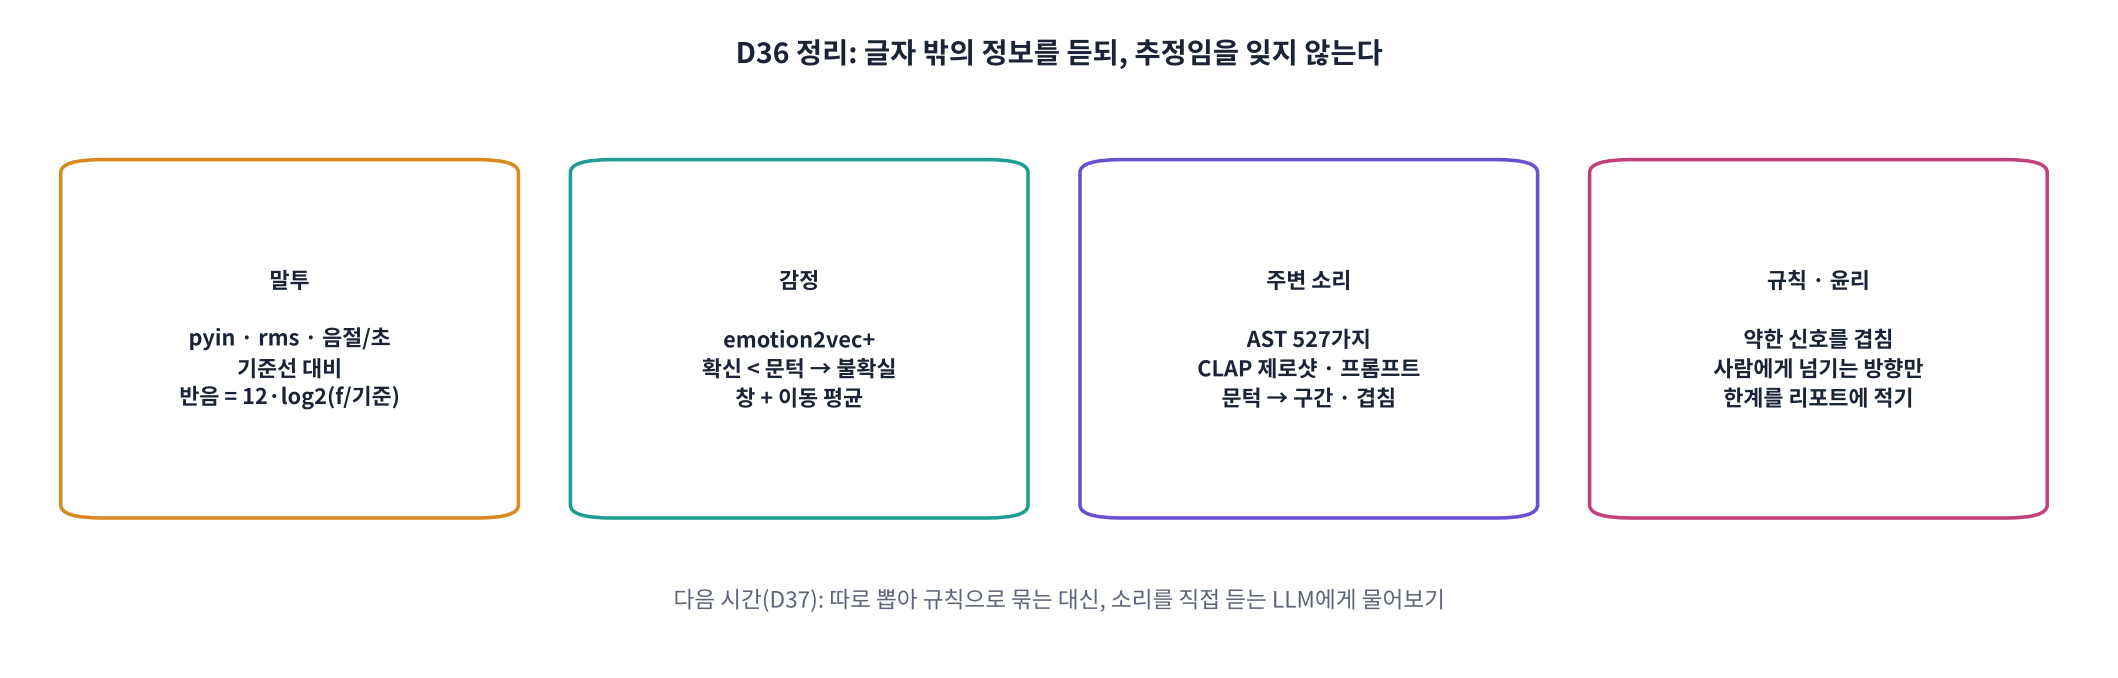

| 오늘 만든 것 | 핵심 | 한계 |
|---|---|---|
| `prosody` · `arousal` | 높낮이 · 크기 · 말속도를 **기준선과 비교** | 들뜬 이유는 모름. 처음부터 들뜬 사람을 놓침 |
| `emotion` · `decide` | 감정 확률, 확신이 낮으면 **불확실** | 연기 음성으로 학습. 글은 읽지 않음 |
| `windows` · `smooth` | 창으로 잘라 **타임라인**, 이동 평균 | 안정될수록 반응이 늦어짐 |
| `ast_top` · `zero_shot` | 정해진 목록 vs **글로 묻기** | 프롬프트에 따라 달라짐. 보기에 없으면 엉뚱한 답 |
| `detect` · `overlap` | 문턱 + 이어진 창 → **구간** | 놓침과 오경보의 맞바꿈 |
| `escalate` · 리포트 | 약한 신호를 겹쳐 **사람에게 넘기기** | 불이익을 주는 결정에는 쓰지 않음 |

**다음 시간(D37)**: 오늘은 말투 · 감정 · 주변 소리를 **따로따로** 뽑아 규칙으로 묶었습니다. 다음 시간에는 소리를 **직접 듣는 LLM**(Audio LLM)에게 같은 통화를 들려주고 "손님 기분이 어땠나요? 뒤에서 무슨 소리가 났나요?"라고 물어, 오늘 만든 방식과 비교합니다.